# Part A — Rebuild nine charts, then take them apart (36 marks)

Nine analysts, nine claims, nine charts that are **arithmetically correct and still wrong**. For each case: **rebuild** it from the recipe and hit the self-check number → **the conclusion and the decoy** → **the mechanism** (which channel or boundary lies, with the number that proves it) → **the redesign**, actually plotted.

All data is synthetic, generated for CDB601220. Figures are saved to `figures/` at 300 dpi (`partA_caseN_rebuild.png`, `partA_caseN_redesign.png`).

**Which redesigns are *not* a change of chart type?** Cases **3** and **4** — the redesign is the *same parallel-coordinates plot* with a different decision inside it (the scaling, and the axis order). Cases 1 and 5 also keep their chart type (bubble chart, map) and change a parameter (the size scale, the class scheme), but there the picture changes visibly; in 3 and 4 only the decision changes.

**Brief vs data, one discrepancy** (reported where it appears): the Case 1 self-check says the largest mark is 589× the smallest *in area* with 9 countries below one point². With `s = pop_m**2` I get **346,921×** in area (589× is the *population* ratio) and **3** countries below 1 pt² (9 countries have populations under 2.0 M, but `pop²` only drops under 1 below 1.0 M).

In [1]:
import os, sys, json, itertools
sys.path.insert(0, os.getcwd())          # notebook sits beside vizlib.py / geolib.py
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import geolib as g                        # Week 5 toolkit (built on vizlib)
g.style_defaults()                        # Week 3 look, 300 dpi export default
DATA, FIG = "data/", "figures/"
os.makedirs(FIG, exist_ok=True)
PAL = g.PALETTE

def corr_chain(df, cols):
    """geolib.corr_chain with one line changed: newer pandas hands back a read-only
    array, so np.fill_diagonal on r.values raises. Same greedy rule (slide 24)."""
    cols = list(cols)
    r = df[cols].corr().abs()
    a = r.to_numpy().copy(); np.fill_diagonal(a, 0.0)
    r = pd.DataFrame(a, index=cols, columns=cols)
    i, j = np.unravel_index(np.argmax(a), a.shape)
    order = [cols[i], cols[j]]
    while len(order) < len(cols):
        rest = [c for c in cols if c not in order]
        order.append(max(rest, key=lambda c: r.loc[order[-1], c]))
    return order

NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]

import textwrap
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from scipy import stats

hi = pd.read_csv(DATA + "health_indicators.csv")
dh = pd.read_csv(DATA + "district_health.csv"); dh["rate"] = dh.cases / dh.population * 1e5
feats = g.read_geojson(DATA + "districts.geojson")
LAT_TS = g._collection_lat_ts(feats)

def flat_map(ax, vals, vmin, vmax, cmap="Blues", lw=0.4):
    """Districts coloured on a CONTINUOUS ramp with fixed bounds (no classes)."""
    cm = plt.get_cmap(cmap); patches, cols = [], []
    for f in feats:
        x, y = g._project_ring(list(f["ring"]), "equal_area", LAT_TS)
        patches.append(MplPolygon(np.column_stack([x, y]), closed=True))
        cols.append(cm((vals[f["code"]] - vmin) / (vmax - vmin)))
    ax.add_collection(PatchCollection(patches, facecolors=cols, edgecolors="white", linewidths=lw))
    ax.autoscale_view(); ax.set_aspect("equal"); ax.set_axis_off()

def save(fig, name, note):
    g.save_fig(fig, FIG + name, note="\n".join(textwrap.wrap(note, 170)))

SRC = "Synthetic data generated for CDB601220."

---
## Case 1 · "Population and healthcare access are unrelated — the large countries are spread right across the range"
`health_indicators.csv` · recipe: `ax.scatter(df.gdp_pc, df.healthcare_access, s=df.pop_m**2)`, log x

### 1a · Rebuild

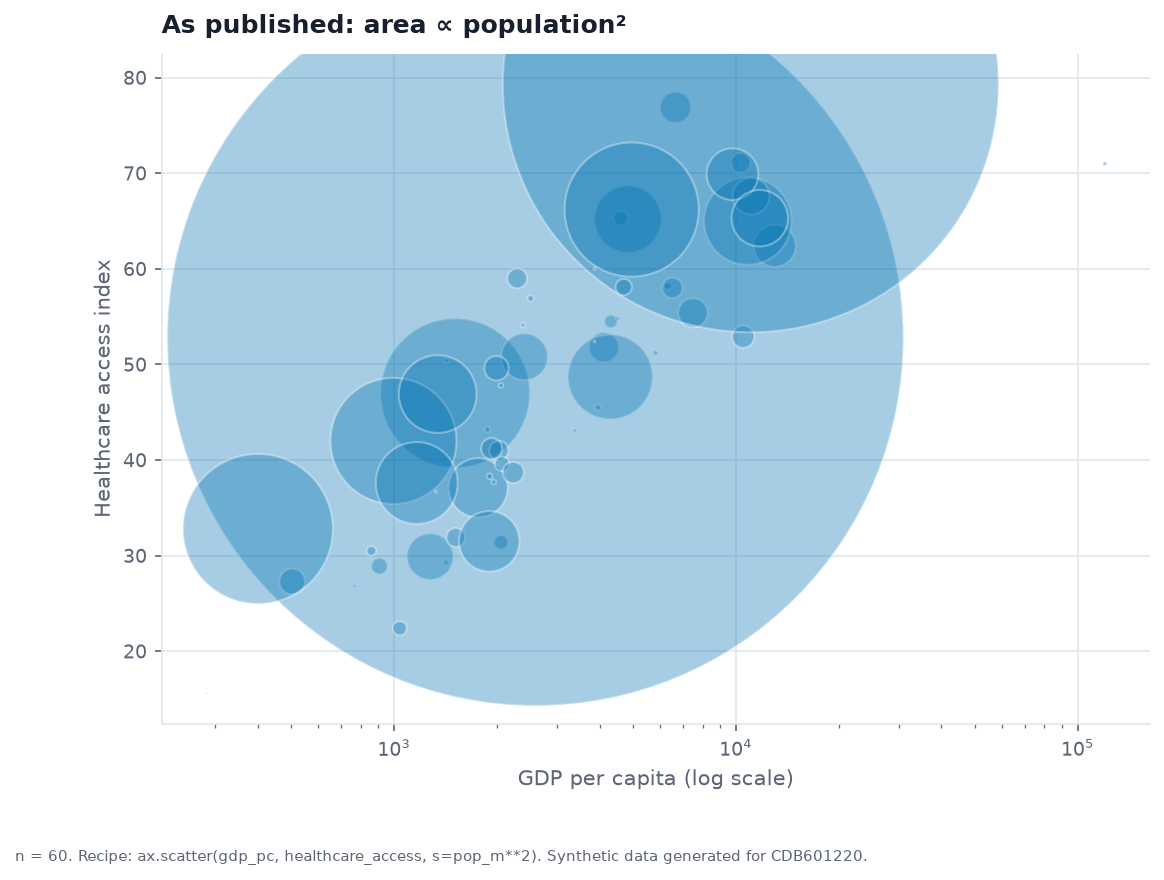

marks drawn: 60
area ratio, largest / smallest mark : 346,921x   <- brief says 589x; 589x is the POPULATION ratio (589x)
countries drawn SMALLER than 1 point² : 3   <- brief says 9
countries with population < 2.0 M     : 9   (the brief's 9; pop² only drops under 1 pt² below 1.0 M -> 3)
largest mark: 124,892 pt² -> diameter 399 pt = 5.5 inches


In [2]:
s_pub = hi.pop_m.to_numpy() ** 2                      # the published recipe: pop SQUARED passed to s (which is already AREA)
fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.scatter(hi.gdp_pc, hi.healthcare_access, s=s_pub, color=PAL["series"][0], alpha=0.35, edgecolor="white")
ax.set_xscale("log"); ax.set_xlabel("GDP per capita (log scale)"); ax.set_ylabel("Healthcare access index")
ax.set_title("As published: area ∝ population²", loc="left")
save(fig, "partA_case1_rebuild.png", "n = 60. Recipe: ax.scatter(gdp_pc, healthcare_access, s=pop_m**2). " + SRC)
plt.show()

print(f"marks drawn: {len(hi)}")
print(f"area ratio, largest / smallest mark : {s_pub.max()/s_pub.min():,.0f}x   <- brief says 589x; 589x is the POPULATION ratio ({hi.pop_m.max()/hi.pop_m.min():.0f}x)")
print(f"countries drawn SMALLER than 1 point² : {(s_pub < 1).sum()}   <- brief says 9")
print(f"countries with population < 2.0 M     : {(hi.pop_m < 2.0).sum()}   (the brief's 9; pop² only drops under 1 pt² below 1.0 M -> {(hi.pop_m < 1.0).sum()})")
print(f"largest mark: {s_pub.max():,.0f} pt² -> diameter {2*np.sqrt(s_pub.max()/np.pi):.0f} pt = {2*np.sqrt(s_pub.max()/np.pi)/72:.1f} inches")

### 1b · The conclusion and the decoy

In [3]:
# Which marks sit completely under the largest circle? (display-space geometry from the drawn figure)
fig.canvas.draw()
xy = ax.transData.transform(np.column_stack([hi.gdp_pc, hi.healthcare_access]))
big = hi.pop_m.idxmax()
r_px = np.sqrt(s_pub[big] / np.pi) * fig.dpi / 72
inside = np.hypot(*(xy - xy[big]).T) < r_px
print(f"{hi.loc[big,'country']} ({hi.pop_m[big]} M) is drawn {2*r_px/fig.dpi:.1f} in across; it covers the centres of {inside.sum()-1} other countries")
print("\nthe 8 largest countries and their access scores:")
print(hi.nlargest(8, "pop_m")[["country", "region", "pop_m", "healthcare_access"]].to_string(index=False))
print(f"\nr(pop_m, healthcare_access) = {hi.pop_m.corr(hi.healthcare_access):+.2f}   r(log pop, access) = {np.log(hi.pop_m).corr(hi.healthcare_access):+.2f}")
print(f"access range of the 8 largest: {hi.nlargest(8,'pop_m').healthcare_access.min()} – {hi.nlargest(8,'pop_m').healthcare_access.max()}  | of all 60: {hi.healthcare_access.min()} – {hi.healthcare_access.max()}")

Wessant (353.4 M) is drawn 5.5 in across; it covers the centres of 57 other countries

the 8 largest countries and their access scores:
 country   region  pop_m  healthcare_access
 Wessant  Esperia  353.4               52.8
 Vornath  Fenwick  238.0               79.3
Tarrowin  Dravira   71.9               32.8
  Galvia   Andara   71.6               47.0
Fennmark  Dravira   64.4               66.2
 Faldria Borealis   60.5               42.0
 Doreska  Fenwick   42.0               65.0
 Noventa Borealis   40.5               48.7

r(pop_m, healthcare_access) = +0.21   r(log pop, access) = +0.27
access range of the 8 largest: 32.8 – 79.3  | of all 60: 15.6 – 79.3


**Conclusion the chart invites:** "population and healthcare access are unrelated; the biggest countries are scattered across the range."

**The decoy (first objection):** *"Maybe the conclusion is simply true — if the marks overlap, the correlation is still weak."* The correlation really is weak (r ≈ +0.21; +0.27 on log population) and the eight largest countries do span access 32.8–79.3 — **so the claim survives the check; the chart does not.** The chart cannot *show* it: the largest circle alone covers the centres of **57 of the other 59 countries** (printed above) and 3 more are invisible, so the "spread across the range" is read off a handful of blobs, not off the data. The claim happens to be defensible; the evidence presented for it is not.

**The mechanism — the size channel.** `s` already takes *area* in points². Passing `pop_m**2` makes the area go as **population squared**: the area ratio is **346,921×** (not 589×), the largest mark (Wessant, 353 M) is **≈ 5.5 inches across** and covers the centres of 57 other countries, and **3** countries fall below one point² and vanish. Area is the channel, population² is the variable — the legend-less reader converts a 589× population range into an apparent 346,921× one. (Brief's self-check says 589× / 9 countries; the data give 346,921× / 3 — 589× is the population ratio, and 9 is the count under 2.0 M.)

### 1c · The redesign — area ∝ population (affine, floored), legend in people

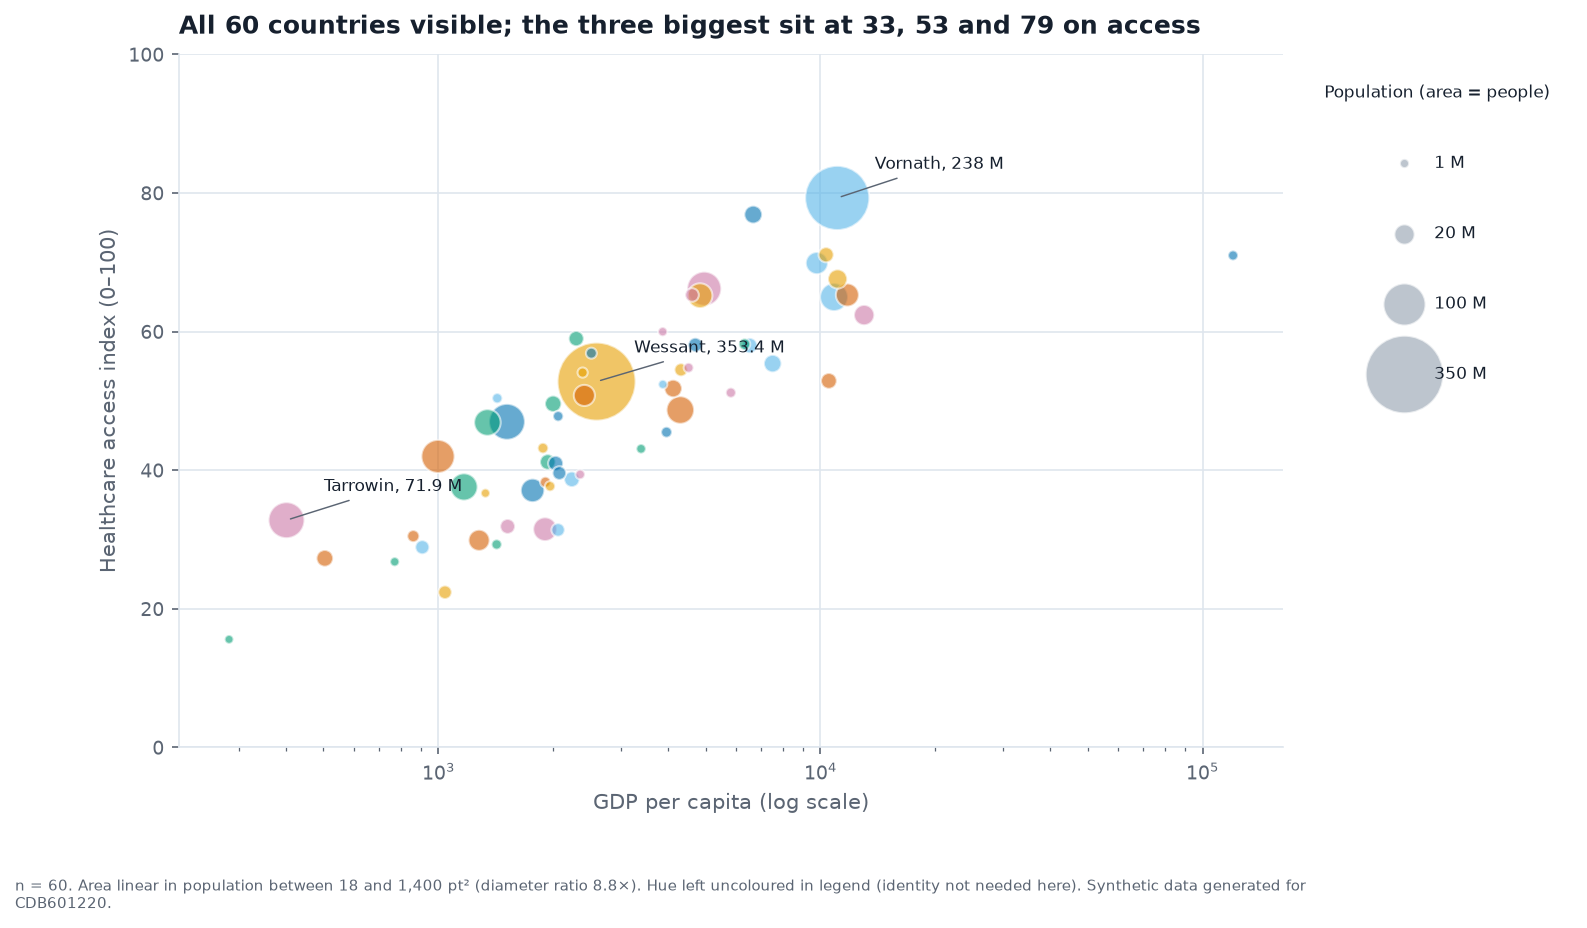

area ratio now 77.8x (diameter 8.8x); marks below 1 pt²: 0


In [4]:
LO, HI = 18, 1400
pop = hi.pop_m.to_numpy()
area = lambda p: LO + (HI - LO) * (np.asarray(p, float) - pop.min()) / (pop.max() - pop.min())
fig, ax = plt.subplots(figsize=(9.5, 6.0))
reg = sorted(hi.region.unique()); HUES = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]; col = dict(zip(reg, HUES))
o = np.argsort(-pop)
ax.scatter(hi.gdp_pc.iloc[o], hi.healthcare_access.iloc[o], s=area(pop)[o], c=[col[r] for r in hi.region.iloc[o]],
           alpha=0.6, edgecolor="white", zorder=3)
ax.set_xscale("log"); ax.set_ylim(0, 100); ax.set_xlabel("GDP per capita (log scale)"); ax.set_ylabel("Healthcare access index (0–100)")
for nm in ["Wessant", "Vornath", "Tarrowin"]:
    r_ = hi[hi.country == nm].iloc[0]
    ax.annotate(f"{nm}, {r_.pop_m:g} M", (r_.gdp_pc, r_.healthcare_access), xytext=(18, 14), textcoords="offset points", fontsize=8,
                arrowprops=dict(arrowstyle="-", lw=.7, color=PAL["ink_soft"]))
hs = [ax.scatter([], [], s=area(v), color=PAL["muted"], alpha=.65, edgecolor="white", label=f"{v:g} M") for v in (1, 20, 100, 350)]
ax.legend(handles=hs, title="Population (area = people)", loc="upper left", bbox_to_anchor=(1.01, 1), labelspacing=3.2, borderpad=1.3, fontsize=8, title_fontsize=8)
ax.set_title("All 60 countries visible; the three biggest sit at 33, 53 and 79 on access", loc="left")
save(fig, "partA_case1_redesign.png", "n = 60. Area linear in population between 18 and 1,400 pt² (diameter ratio 8.8×). Hue left uncoloured in legend (identity not needed here). " + SRC)
plt.show()
print(f"area ratio now {area(pop).max()/area(pop).min():.1f}x (diameter {np.sqrt(area(pop).max()/area(pop).min()):.1f}x); marks below 1 pt²: {(area(pop) < 1).sum()}")

---
## Case 2 · "The outbreak is concentrated in the three districts around the capital"
`district_health.csv` + `districts.geojson` · recipe: join on `code`, colour by `cases`, five natural breaks, blue ramp, list the top three

### 2a · Rebuild

districts: 24 | join failures: 0 | cases 30,564 | population 57,857,000


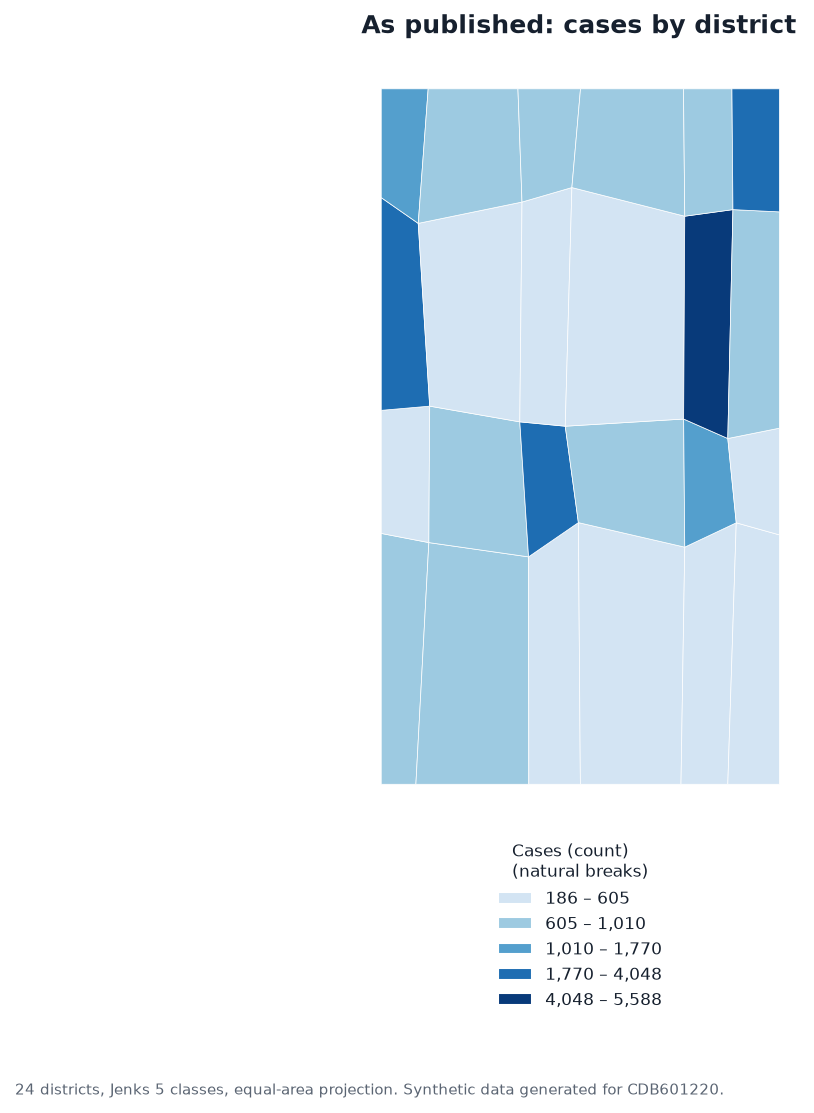

top three by count: ['D17', 'D13', 'D09'] ['Qilabad', 'Mehrabad', 'Ilyaspur']


In [5]:
fe = {f["code"] for f in feats}; assert fe == set(dh.code), "join problem"
print(f"districts: {len(dh)} | join failures: {len(fe ^ set(dh.code))} | cases {dh.cases.sum():,} | population {dh.population.sum():,}")
fig, ax = plt.subplots(figsize=(7.5, 7.5))
e = g.choropleth(ax, feats, dict(zip(dh.code, dh.cases)), "natural", 5, legend_title="Cases (count)\n(natural breaks)", fmt="{:,.0f}",
                 legend_loc="upper center", legend_anchor=(0.5, -0.01))
ax.set_title("As published: cases by district", loc="left")
fig.subplots_adjust(bottom=0.2)
save(fig, "partA_case2_rebuild.png", "24 districts, Jenks 5 classes, equal-area projection. " + SRC)
plt.show()
top = dh.nlargest(3, "cases")
print("top three by count:", top.code.tolist(), top.district.tolist())

### 2b · The conclusion and the decoy

In [6]:
pooled = dh.cases.sum() / dh.population.sum() * 1e5
print(f"pooled national rate: {pooled:.1f} per 100,000")
print(top[["code", "district", "cases", "population", "rate"]].round(1).to_string(index=False))
print(f"\nthe top-3 districts hold {top.cases.sum()/dh.cases.sum():.1%} of the cases and {top.population.sum()/dh.population.sum():.1%} of the population")
print(f"r(cases, population) = {dh.cases.corr(dh.population):+.3f}     r(rate, population) = {dh.rate.corr(dh.population):+.3f}")
topr = dh.nlargest(3, "rate")
print("\ntop three by RATE:", topr.code.tolist(), topr.district.tolist(), "| overlap with the count list:", len(set(top.code) & set(topr.code)))
print(f"populations: count-leaders {top.population.min()/1e6:.1f}–{top.population.max()/1e6:.1f} M, rate-leaders {topr.population.min()/1e6:.1f}–{topr.population.max()/1e6:.1f} M")
print("centroids of the count-leaders (lon, lat):", top[["lon", "lat"]].round(1).values.tolist(), "-> not adjacent")

pooled national rate: 52.8 per 100,000
code district  cases  population  rate
 D17  Qilabad   5588    10966000  51.0
 D13 Mehrabad   4048     6327000  64.0
 D09 Ilyaspur   3437     6886000  49.9

the top-3 districts hold 42.8% of the cases and 41.8% of the population
r(cases, population) = +0.986     r(rate, population) = -0.000

top three by RATE: ['D19', 'D20', 'D21'] ['Sibbi East', 'Tarmak', 'Ushkan'] | overlap with the count list: 0
populations: count-leaders 6.3–11.0 M, rate-leaders 1.1–1.8 M
centroids of the count-leaders (lon, lat): [[72.6, 31.8], [66.4, 32.0], [69.4, 29.0]] -> not adjacent


**Conclusion invited:** "the outbreak is concentrated in three districts" (D17, D13, D09 — the darkest on the count map).

**The decoy (first objection):** *"Those three really do have the most cases — the outbreak must be there."* They do have the most cases — but ruled out as evidence of concentration: they hold **42.8%** of the cases and **41.8%** of the population, i.e. cases are *proportional* to people; two of the three (D17 51.0, D09 49.9) are actually **below** the national rate of 52.8 per 100,000, and the third (D13, 64.0) is 21% above it. Their centroids are also far apart (lon 66.4–72.6, lat 29.0–32.0), so there is no "cluster around" anything.

**The mechanism — the denominator.** `cases` is a count and population varies 23×; **r(cases, population) = +0.986**, while r(rate, population) = −0.000. A count choropleth is a population map. The top-three-by-rate (**D19, D20, D21**) share **zero** districts with the count list and hold only 1.1–1.8 M people against 6.3–11.0 M.

### 2c · The redesign — rate per 100,000, with the count shown against population

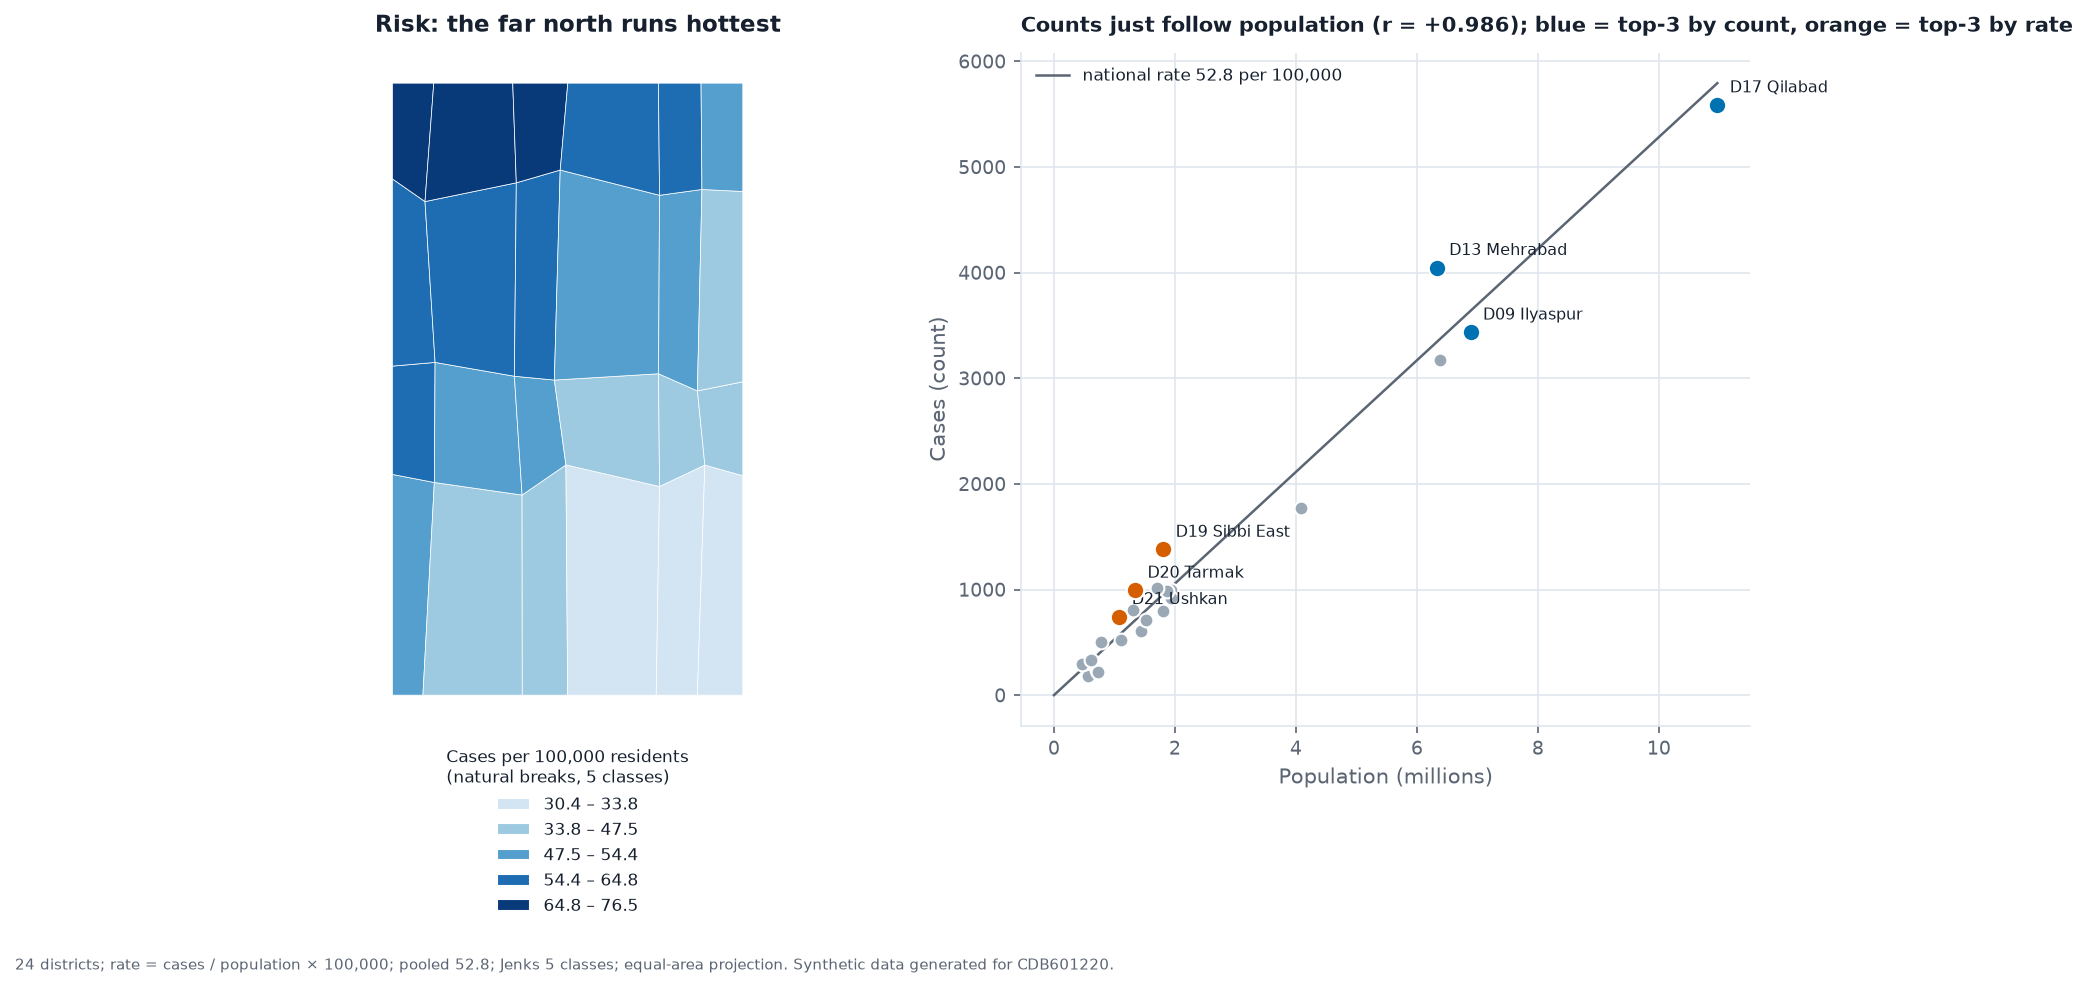

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6.6), gridspec_kw={"width_ratios": [0.9, 1]}); fig.subplots_adjust(bottom=0.2, wspace=0.18)
g.choropleth(a1, feats, dict(zip(dh.code, dh.rate)), "natural", 5, legend_title="Cases per 100,000 residents\n(natural breaks, 5 classes)",
             fmt="{:.1f}", legend_loc="upper center", legend_anchor=(0.5, -0.01))
a1.set_title("Risk: the far north runs hottest", loc="left", fontsize=11)
a2.scatter(dh.population / 1e6, dh.cases, s=44, color=PAL["muted"], edgecolor="white", zorder=3)
xs = np.linspace(0, dh.population.max() / 1e6, 50); a2.plot(xs, pooled / 1e5 * xs * 1e6, color=PAL["ink_soft"], lw=1.2, label=f"national rate {pooled:.1f} per 100,000")
for c_, color in [(top, PAL["series"][0]), (topr, PAL["highlight"])]:
    a2.scatter(c_.population / 1e6, c_.cases, s=70, color=color, edgecolor="white", zorder=4)
    for _, r_ in c_.iterrows(): a2.annotate(f"{r_.code} {r_.district}", (r_.population / 1e6, r_.cases), xytext=(6, 6), textcoords="offset points", fontsize=7.5)
a2.set_xlabel("Population (millions)"); a2.set_ylabel("Cases (count)"); a2.legend(loc="upper left", fontsize=8)
a2.set_title("Counts just follow population (r = +0.986); blue = top-3 by count, orange = top-3 by rate", loc="left", fontsize=10)
save(fig, "partA_case2_redesign.png", f"24 districts; rate = cases / population × 100,000; pooled {pooled:.1f}; Jenks 5 classes; equal-area projection. " + SRC)
plt.show()

---
## Case 3 · "GDP per capita barely varies across the sample"
`health_indicators.csv` · recipe: min–max scale all five numeric columns, parallel coordinates, observe that `gdp_pc` is almost flat along the bottom

### 3a · Rebuild

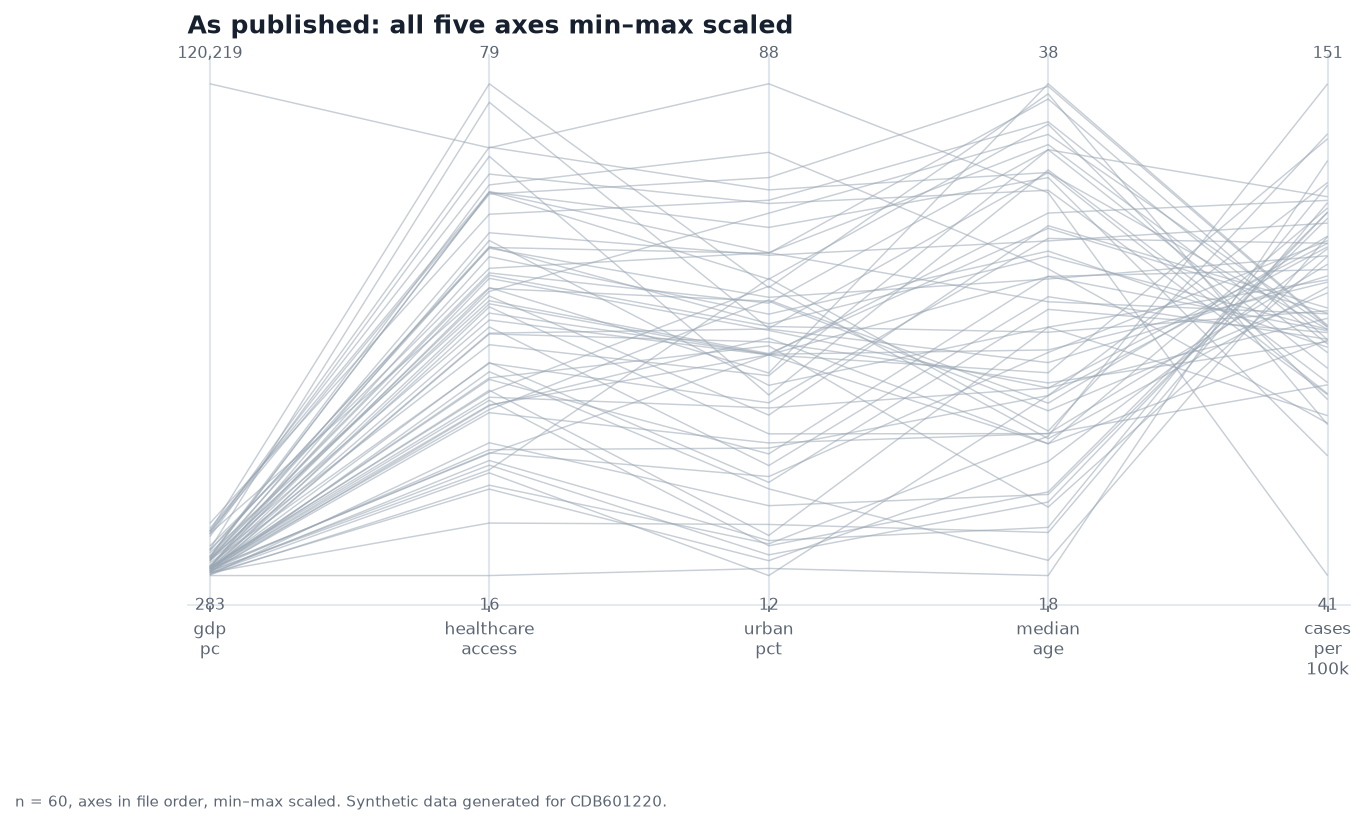

58 of 60 countries sit below 0.10 on gdp_pc   (brief: 58)   median 0.017   (brief: 0.017)


In [8]:
fig, ax = plt.subplots(figsize=(10, 5.4)); fig.subplots_adjust(bottom=0.2)
N = g.pcp(ax, hi, NUM, "minmax")                       # file order, min–max — the published recipe
ax.set_title("As published: all five axes min–max scaled", loc="left")
save(fig, "partA_case3_rebuild.png", "n = 60, axes in file order, min–max scaled. " + SRC)
plt.show()
mm = N["gdp_pc"]
print(f"{(mm < 0.10).sum()} of 60 countries sit below 0.10 on gdp_pc   (brief: 58)   median {mm.median():.3f}   (brief: 0.017)")

### 3b · The conclusion and the decoy

In [9]:
srt = hi.sort_values("gdp_pc", ascending=False)
print(srt.head(3)[["country", "region", "gdp_pc", "pop_m", "healthcare_access", "urban_pct", "median_age"]].to_string(index=False))
print(f"\nmax is {srt.gdp_pc.iloc[0]/srt.gdp_pc.iloc[1]:.1f}x the second-highest")
print("is the outlier a data error? its other columns:", srt.iloc[0][["healthcare_access", "urban_pct", "median_age"]].to_dict(),
      "vs 2nd-highest-access country in the file", hi.healthcare_access.nlargest(2).iloc[1])
rest = hi[hi.gdp_pc < hi.gdp_pc.max()].gdp_pc
print(f"\nthe other 59 countries span ${rest.min():,} – ${rest.max():,} = {rest.max()/rest.min():.0f}x (multiplicative)")
mm2 = (rest - rest.min()) / (rest.max() - rest.min())
print(f"drop the outlier and re-scale: median {mm2.median():.3f}, {(mm2 < 0.10).sum()} of 59 still below 0.10")
lg = np.log10(hi.gdp_pc); lgs = (lg - lg.min()) / (lg.max() - lg.min())
print(f"log10 then min–max (all 60): median {lgs.median():.3f}, {(lgs < 0.10).sum()} of 60 below 0.10")
print(f"rank scaling: median {g.scale_frame(hi, NUM, 'rank')['gdp_pc'].median():.3f}")

   country   region  gdp_pc  pop_m  healthcare_access  urban_pct  median_age
   Aldonia   Andara  120219    1.9               71.0       88.0        33.4
Brightmoor  Dravira   13009   20.1               62.4       70.0        36.2
  Durnhill Borealis   11758   27.1               65.3       61.9        35.3

max is 9.2x the second-highest
is the outlier a data error? its other columns: {'healthcare_access': 71.0, 'urban_pct': 88.0, 'median_age': 33.4} vs 2nd-highest-access country in the file 76.9

the other 59 countries span $283 – $13,009 = 46x (multiplicative)
drop the outlier and re-scale: median 0.162, 16 of 59 still below 0.10
log10 then min–max (all 60): median 0.351, 3 of 60 below 0.10
rank scaling: median 0.508


**Conclusion invited:** "GDP per capita barely varies — everyone is about the same."

**The decoy (first objection):** *"The outlier is probably a data-entry error; delete it and the problem goes away."* Ruled out: Aldonia ($120,219) has a small population (1.9 M), 88% urban, access 71 and median age 33 — a coherent small rich state, not a typo. And **deleting it does not rescue the picture**: with the 59 others re-scaled, the median is still just 0.162 (so half the countries still sit in the bottom sixth of the axis; 16 of the 59 are still below 0.10), because the *real* spread among the 59 is **46× ($283 → $13,009)** — multiplicative, not additive.

**The mechanism — the scaling.** Min–max pins the top of the axis to a single country that is **9.2× the next highest**, so **58 of 60 countries fall below 0.10 and the median is 0.017**: the axis is a ruler for one country. GDP in this sample varies enormously — the chart spent its entire range on one point.

### 3c · The redesign — same plot, different scaling decision (percentile rank)

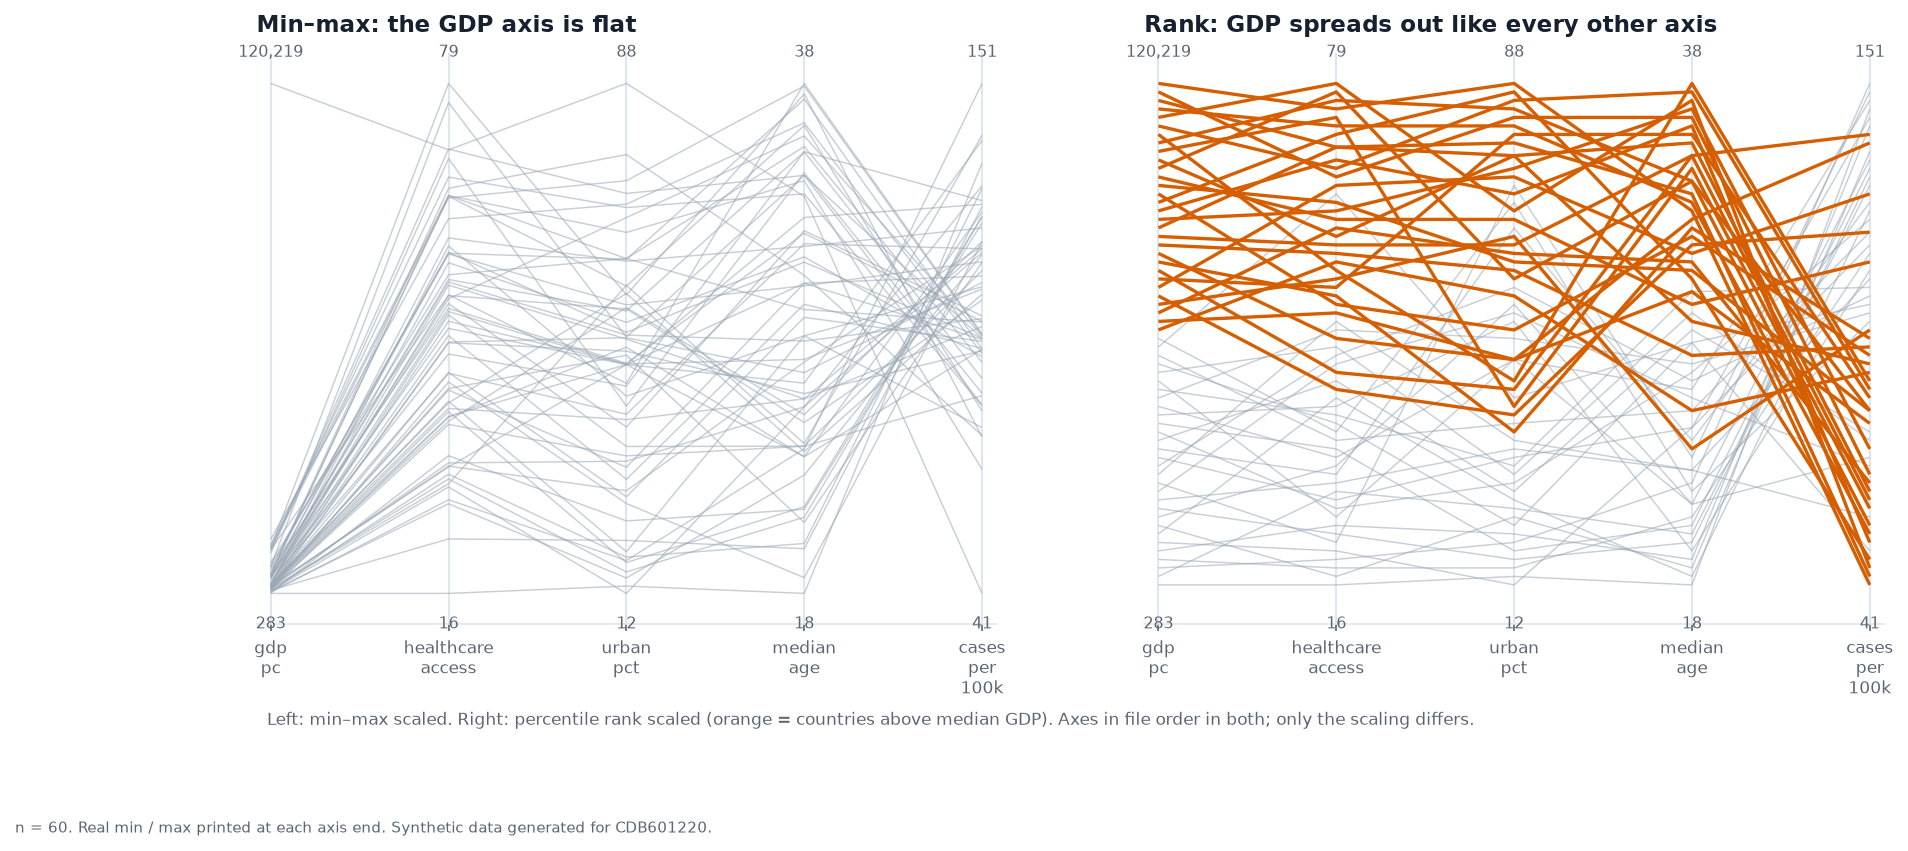

median gdp_pc position — min–max: 0.017 | rank: 0.508 | log10 + min–max: 0.351


In [10]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6), sharey=True); fig.subplots_adjust(bottom=0.2)
g.pcp(a1, hi, NUM, "minmax"); a1.set_title("Min–max: the GDP axis is flat", loc="left", fontsize=11)
g.pcp(a2, hi, NUM, "rank", highlight=(hi.gdp_pc >= hi.gdp_pc.median()).to_numpy());  a2.set_title("Rank: GDP spreads out like every other axis", loc="left", fontsize=11)
fig.text(0.13, 0.08, "Left: min–max scaled. Right: percentile rank scaled (orange = countries above median GDP). Axes in file order in both; only the scaling differs.", fontsize=8, color=PAL["ink_soft"])
save(fig, "partA_case3_redesign.png", "n = 60. Real min / max printed at each axis end. " + SRC)
plt.show()
print("median gdp_pc position — min–max: %.3f | rank: %.3f | log10 + min–max: %.3f" % (mm.median(), g.scale_frame(hi, NUM, 'rank')['gdp_pc'].median(), lgs.median()))

---
## Case 4 · "Healthcare access and case rate are unrelated — there is no crossing pattern between them"
`health_indicators.csv` · recipe: parallel coordinates, columns in the order they appear in the file, min–max scaled

### 4a · Rebuild

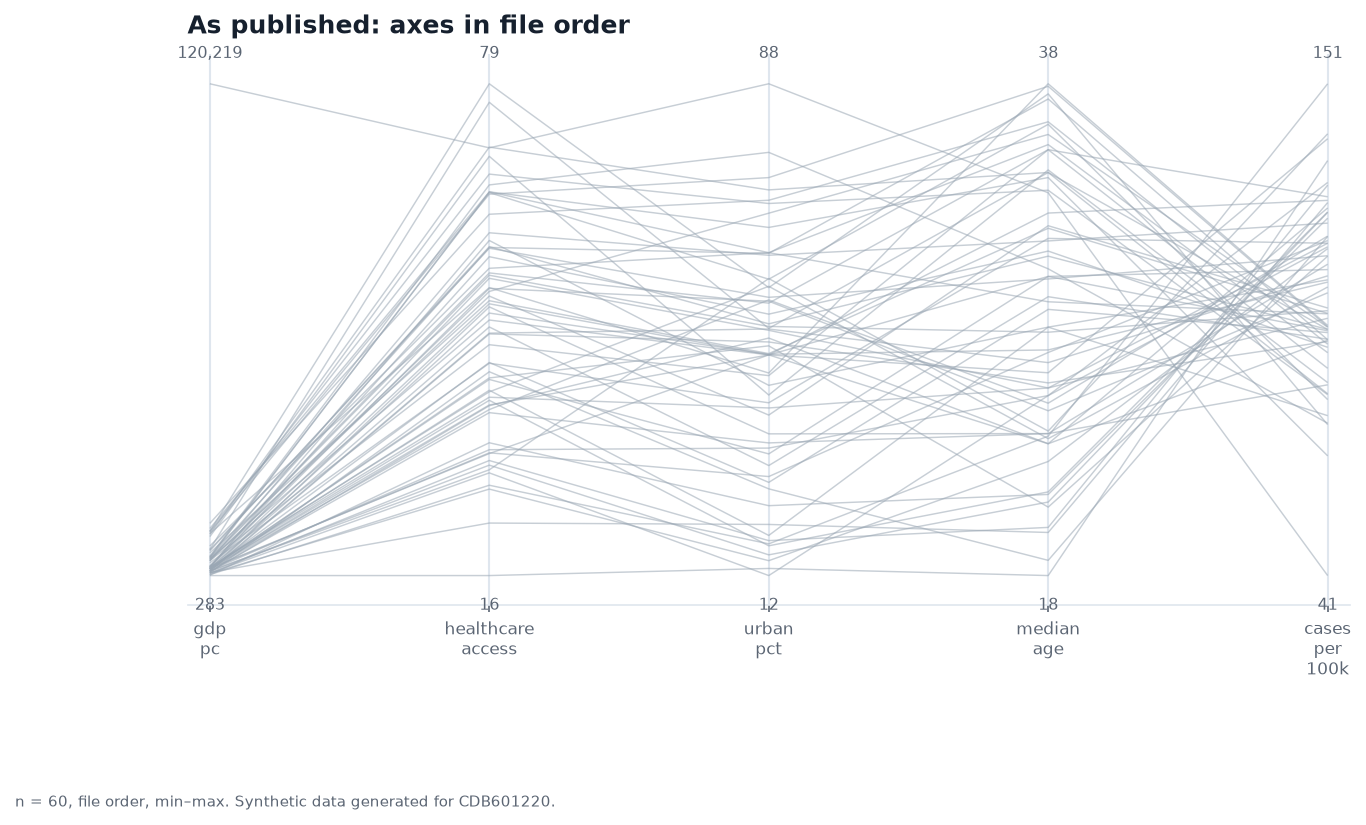

axes: ['gdp_pc', 'healthcare_access', 'urban_pct', 'median_age', 'cases_per_100k']
healthcare_access is axis 2, cases_per_100k is axis 5 -> 3 apart; between them: ['urban_pct', 'median_age']


In [11]:
order_file = NUM
fig, ax = plt.subplots(figsize=(10, 5.4)); fig.subplots_adjust(bottom=0.2)
g.pcp(ax, hi, order_file, "minmax")
ax.set_title("As published: axes in file order", loc="left")
save(fig, "partA_case4_rebuild.png", "n = 60, file order, min–max. " + SRC)
plt.show()
i, j = order_file.index("healthcare_access"), order_file.index("cases_per_100k")
print("axes:", order_file)
print(f"healthcare_access is axis {i+1}, cases_per_100k is axis {j+1} -> {abs(i-j)} apart; between them: {order_file[i+1:j]}")

### 4b · The conclusion and the decoy

In [12]:
R = hi[NUM].corr()
r_ac = R.loc["healthcare_access", "cases_per_100k"]
rho = stats.spearmanr(hi.healthcare_access, hi.cases_per_100k)
print(f"r(access, cases) = {r_ac:+.3f}   Spearman rho = {rho.statistic:+.3f}   p = {stats.pearsonr(hi.healthcare_access, hi.cases_per_100k).pvalue:.1e}")
pairs_file = [(a, b) for a, b in zip(order_file[:-1], order_file[1:])]
print("\nadjacent pairs in FILE order and their |r|:")
for a, b in pairs_file: print(f"  {a:18s}–{b:18s} {abs(R.loc[a,b]):.3f}")
allpairs = R.abs().where(np.triu(np.ones(R.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print(f"\nthe strongest of all 10 pairs: {allpairs.index[0]} (|r| = {allpairs.iloc[0]:.3f}); its distance in file order = {abs(i-j)} axes")
chain = corr_chain(hi, NUM)
print("greedy |r| chain:", " -> ".join(chain))
print("adjacent |r| in chain order:", [round(abs(R.loc[a, b]), 3) for a, b in zip(chain[:-1], chain[1:])])
import math
print(f"\n{math.factorial(5)//2} distinct axis orders for 5 axes (reversal is the same picture); the file's order is one of them, chosen by whoever built the CSV")

r(access, cases) = -0.799   Spearman rho = -0.810   p = 1.9e-14

adjacent pairs in FILE order and their |r|:
  gdp_pc            –healthcare_access  0.365
  healthcare_access –urban_pct          0.754
  urban_pct         –median_age         0.644
  median_age        –cases_per_100k     0.587

the strongest of all 10 pairs: ('healthcare_access', 'cases_per_100k') (|r| = 0.799); its distance in file order = 3 axes
greedy |r| chain: healthcare_access -> cases_per_100k -> urban_pct -> median_age -> gdp_pc
adjacent |r| in chain order: [np.float64(0.799), np.float64(0.619), np.float64(0.644), np.float64(0.281)]

60 distinct axis orders for 5 axes (reversal is the same picture); the file's order is one of them, chosen by whoever built the CSV


**Conclusion invited:** "there is no crossing pattern between access and case rate — they are unrelated."

**The decoy (first objection):** *"Min–max scaling or noise is hiding a real relationship."* Ruled out by the data itself: **r = −0.799** (Spearman −0.81, p ≈ 2e-14) — the strongest correlation of all ten pairs in the file. The relationship is as strong as relationships get here, and it is the *same scaling* in both charts, so scaling is not the culprit.

**The mechanism — the axis order.** A parallel coordinates plot can only show a relationship between **adjacent** axes (lines between axis *k* and *k+1* cross or run parallel). In file order the strongest pair is **three apart** — `urban_pct` and `median_age` sit between them — so the lines between those two axes are scrambled by two intermediate axes and no X appears. Five axes have 60 distinct orders and the file's order is one of them, chosen by no one. The greedy rule (slide 24) puts `healthcare_access → cases_per_100k` first and the X appears.

### 4c · The redesign — same plot, same scaling, axis order computed from the data

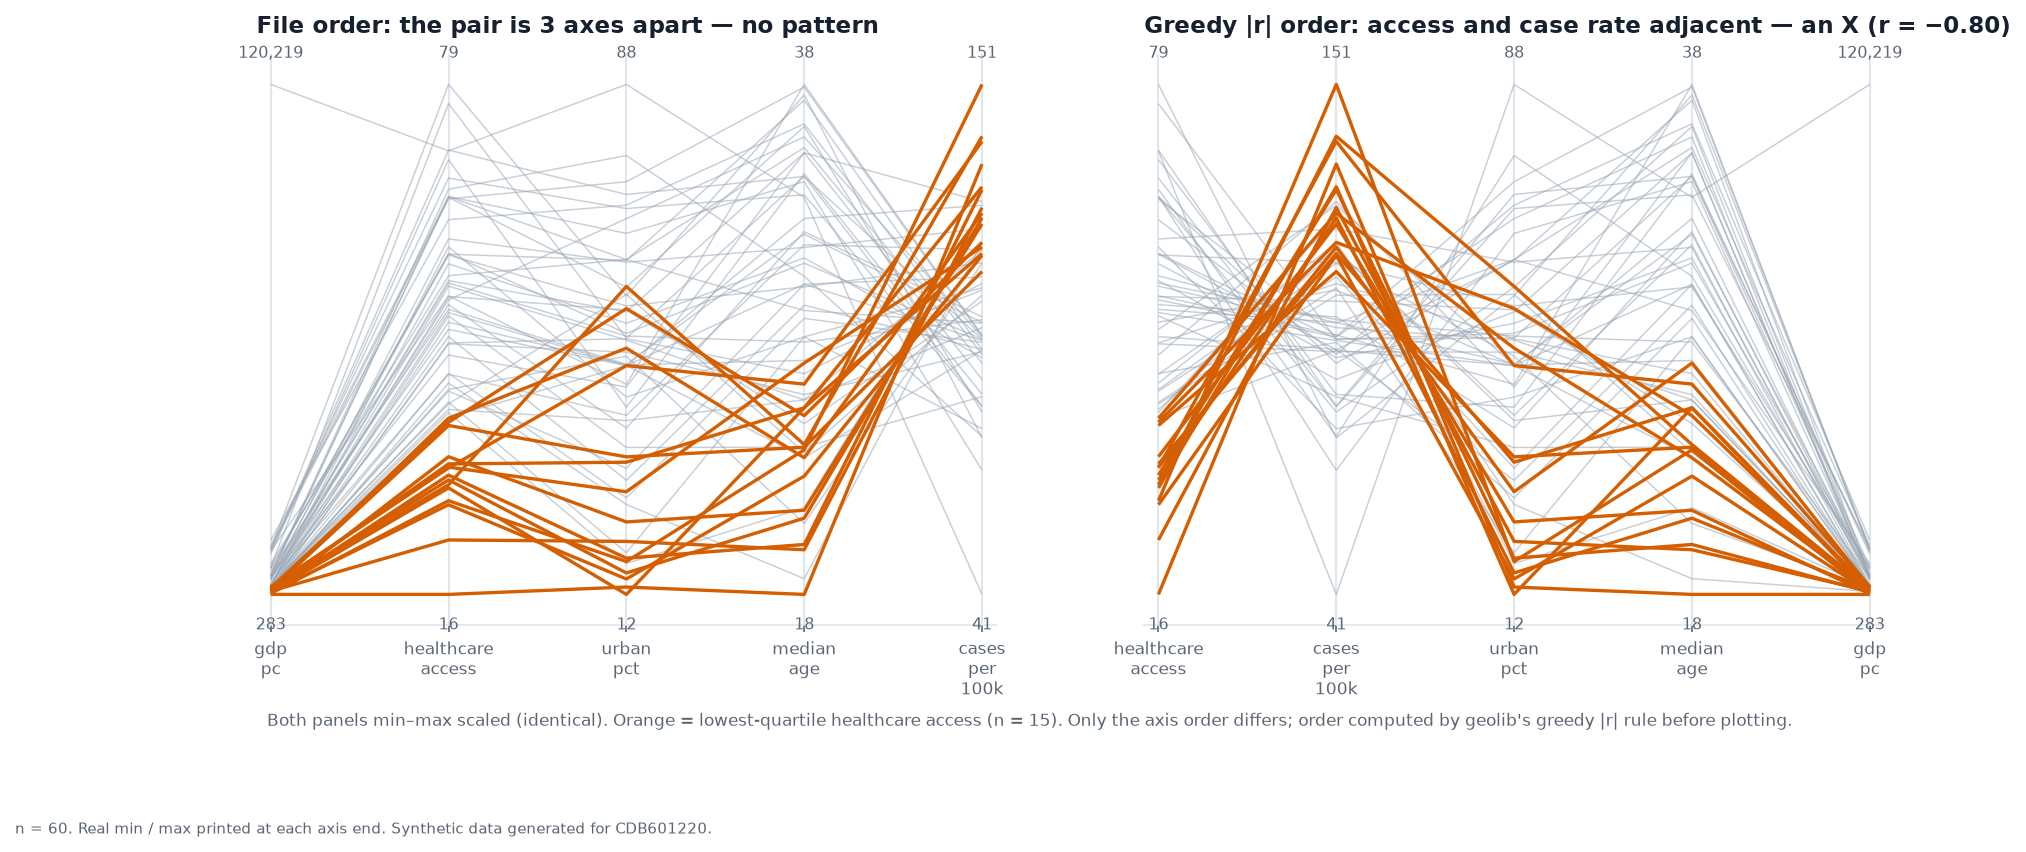

In [13]:
low = (hi.healthcare_access <= hi.healthcare_access.quantile(.25)).to_numpy()        # brush the lowest-access quartile on both panels
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6)); fig.subplots_adjust(bottom=0.2)
g.pcp(a1, hi, order_file, "minmax", highlight=low); a1.set_title("File order: the pair is 3 axes apart — no pattern", loc="left", fontsize=11)
g.pcp(a2, hi, chain, "minmax", highlight=low);      a2.set_title("Greedy |r| order: access and case rate adjacent — an X (r = −0.80)", loc="left", fontsize=11)
fig.text(0.13, 0.08, "Both panels min–max scaled (identical). Orange = lowest-quartile healthcare access (n = %d). Only the axis order differs; order computed by geolib's greedy |r| rule before plotting." % low.sum(), fontsize=8, color=PAL["ink_soft"])
save(fig, "partA_case4_redesign.png", "n = 60. Real min / max printed at each axis end. " + SRC)
plt.show()

---
## Case 5 · "There is a clear five-level gradient in incidence across the federation"
`case05_flat_rates.csv` + `districts.geojson` · recipe: `cases / population * 1e5`, five **quantile** classes, five-step sequential ramp

### 5a · Rebuild

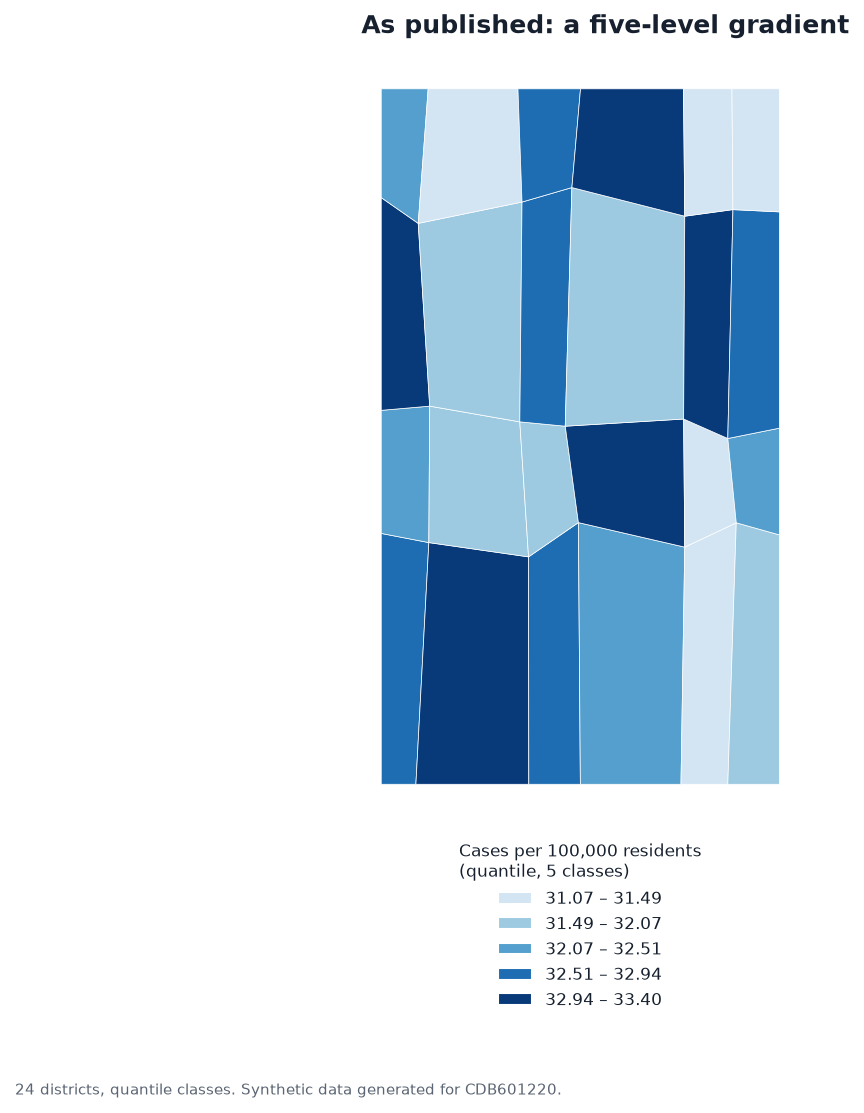

districts 24 | rate 31.07 – 33.40 per 100,000 | spread 7.2% of the mean   (brief: 31.07–33.40, 7.2%)
quantile class edges: [31.07, 31.49, 32.07, 32.51, 32.94, 33.4] | districts per class: [5, 5, 4, 5, 5]


In [14]:
c5 = pd.read_csv(DATA + "case05_flat_rates.csv"); c5["rate"] = c5.cases / c5.population * 1e5
fig, ax = plt.subplots(figsize=(7.5, 7.5)); fig.subplots_adjust(bottom=0.2)
e5 = g.choropleth(ax, feats, dict(zip(c5.code, c5.rate)), "quantile", 5, legend_title="Cases per 100,000 residents\n(quantile, 5 classes)", fmt="{:.2f}",
                  legend_loc="upper center", legend_anchor=(0.5, -0.01))
ax.set_title("As published: a five-level gradient", loc="left")
save(fig, "partA_case5_rebuild.png", "24 districts, quantile classes. " + SRC)
plt.show()
mean5 = c5.rate.mean()
print(f"districts {len(c5)} | rate {c5.rate.min():.2f} – {c5.rate.max():.2f} per 100,000 | spread {(c5.rate.max()-c5.rate.min())/mean5:.1%} of the mean   (brief: 31.07–33.40, 7.2%)")
print("quantile class edges:", np.round(e5, 2).tolist(), "| districts per class:", np.bincount(g.class_of(c5.rate, e5)).tolist())

### 5b · The conclusion and the decoy

In [15]:
p5 = c5.cases.sum() / c5.population.sum(); exp5 = p5 * c5.population
z5 = (c5.cases - exp5) / np.sqrt(exp5)
print(f"pooled rate {p5*1e5:.2f} per 100,000")
print(f"Poisson z-scores per district: min {z5.min():+.2f} max {z5.max():+.2f} | districts beyond ±1.96: {(z5.abs() > 1.96).sum()} of 24")
print(f"chi-square = {(z5**2).sum():.2f} on 23 degrees of freedom (expected ≈ 23 if the rates differed only by chance); P(chi2 <= this) = {stats.chi2.cdf((z5**2).sum(), 23):.1e}")
print(f"class width in rate units: {np.diff(e5).round(2).tolist()}  = {np.diff(e5).mean()/mean5:.1%} of the mean per class")
for sch in ("equal", "quantile", "natural"):
    ee = g.breaks(c5.rate, sch, 5); print(f"{sch:9s} GVF {g.gvf(c5.rate, ee):.3f}  edges {np.round(ee, 2).tolist()}")

pooled rate 32.25 per 100,000
Poisson z-scores per district: min -0.58 max +0.46 | districts beyond ±1.96: 0 of 24
chi-square = 2.30 on 23 degrees of freedom (expected ≈ 23 if the rates differed only by chance); P(chi2 <= this) = 1.3e-08
class width in rate units: [0.41, 0.58, 0.44, 0.43, 0.46]  = 1.4% of the mean per class
equal     GVF 0.961  edges [31.07, 31.54, 32.0, 32.47, 32.93, 33.4]
quantile  GVF 0.959  edges [31.07, 31.49, 32.07, 32.51, 32.94, 33.4]
natural   GVF 0.968  edges [31.07, 31.51, 32.04, 32.55, 33.02, 33.4]


**Conclusion invited:** "incidence falls in five clear steps across the federation."

**The decoy (first objection):** *"The five classes are well separated, so the gradient must be real."* Ruled out: the classes are separated because the classifier **made** them separate. Quantile puts 4–5 districts in every class by construction (printed counts), and the data show **no** evidence of any real difference: the Poisson z-scores run only −0.58 to +0.46 (none beyond ±1.96) and **χ² = 2.30 on 23 degrees of freedom** (P(χ² ≤ 2.30) ≈ 1e-8) — *less* variation between districts than chance alone would produce. (Every goodness-of-fit score looks similarly high — 0.96–0.97 — because even a 2.3-unit spread can be sliced finely.)

**The mechanism — the classification scheme.** The rates run **31.07 to 33.40 per 100,000: a spread of 7.2% of the mean**. Quantile classes stretch the full five-step ramp over that 2.3-per-100,000 range, so each class step is ≈ **1.4% of the mean** — a difference smaller than the Poisson noise in any single district. The map draws a confident dark-to-light staircase across a flat surface. A classification scheme answers "how do I split these numbers?", never "is there a pattern?" — only the spread (and the noise) can answer that.

### 5c · The redesign — the same map, a decision about the scale (fixed, anchored at zero) + the noise band

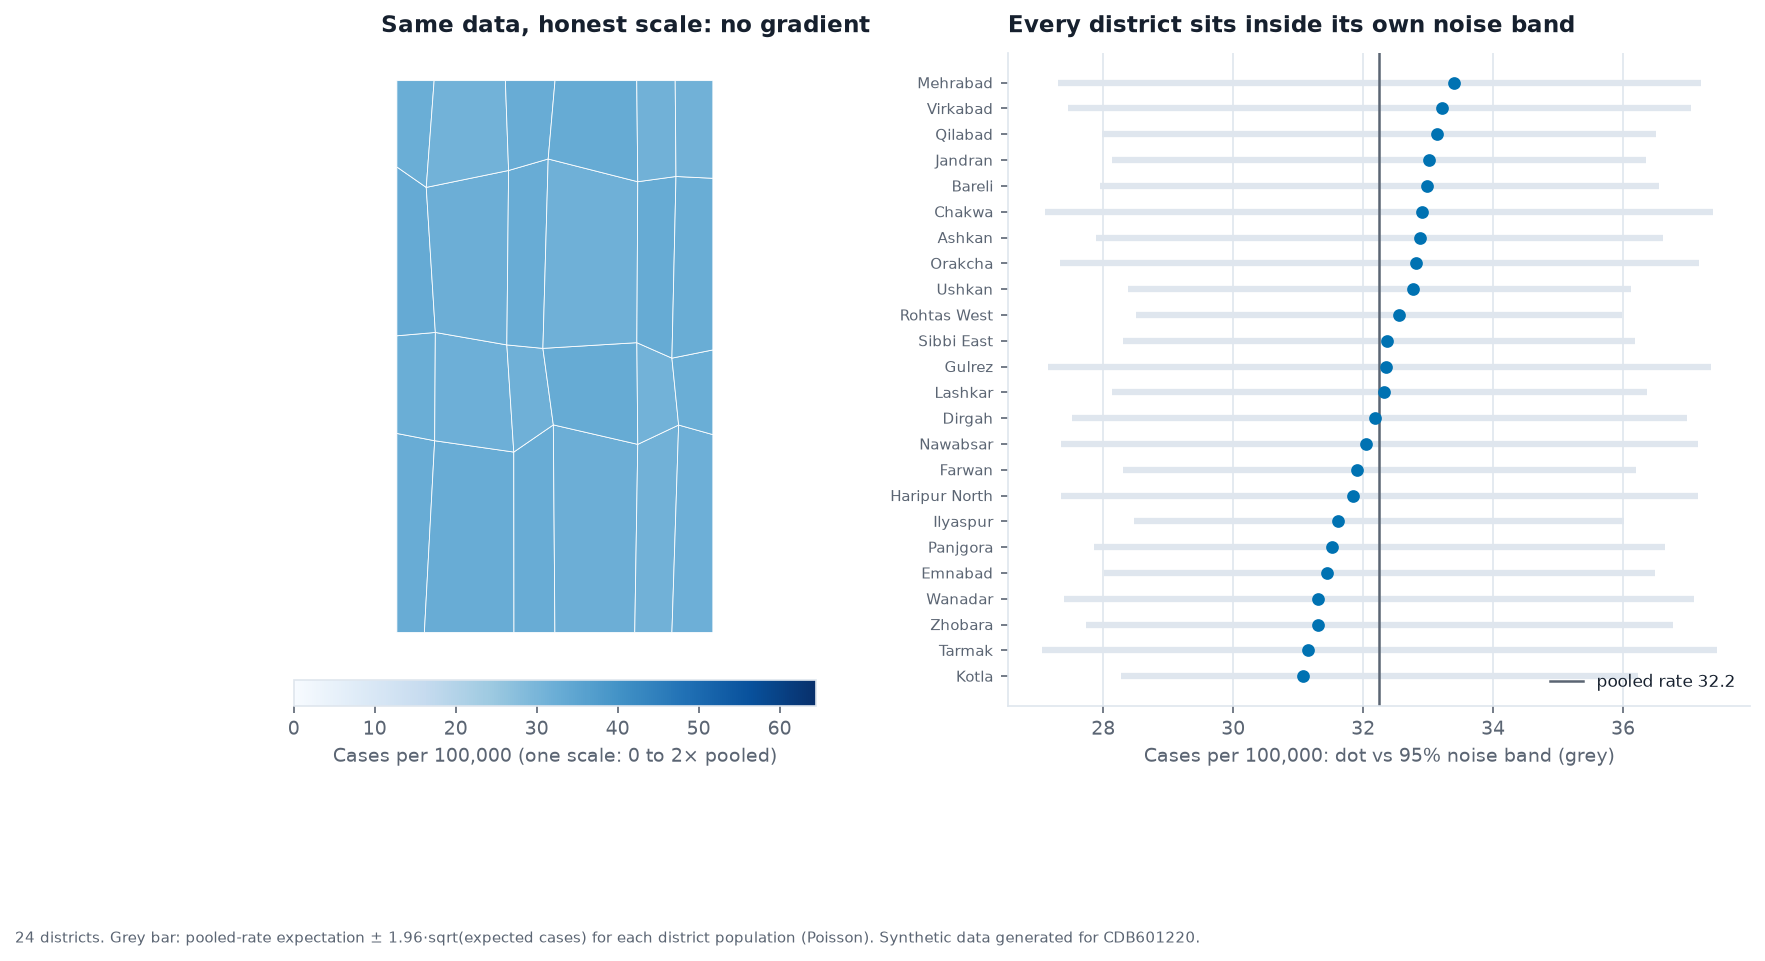

districts whose rate falls outside the 95% band expected from the pooled rate: 0 of 24


In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6.4), gridspec_kw={"width_ratios": [0.85, 1]}); fig.subplots_adjust(bottom=0.2, wspace=0.2)
flat_map(a1, dict(zip(c5.code, c5.rate)), 0, 2 * p5 * 1e5)
sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(0, 2 * p5 * 1e5)); cb = fig.colorbar(sm, ax=a1, orientation="horizontal", fraction=0.04, pad=0.03)
cb.set_label("Cases per 100,000 (one scale: 0 to 2× pooled)", fontsize=9)
a1.set_title("Same data, honest scale: no gradient", loc="left", fontsize=11)
d = c5.assign(lo=lambda t: (exp5 - 1.96*np.sqrt(exp5)) / t.population * 1e5, hi=lambda t: (exp5 + 1.96*np.sqrt(exp5)) / t.population * 1e5).sort_values("rate")
yy = np.arange(len(d))
a2.errorbar(d.rate, yy, xerr=[d.rate - d.lo, d.hi - d.rate], fmt="none", ecolor=PAL["grid"], elinewidth=3, zorder=1)
a2.scatter(d.rate, yy, s=26, color=PAL["series"][0], zorder=3)
a2.axvline(p5 * 1e5, color=PAL["ink_soft"], lw=1.2, label=f"pooled rate {p5*1e5:.1f}")
a2.set_yticks(yy); a2.set_yticklabels(d.district, fontsize=7); a2.grid(axis="y", visible=False)
a2.set_xlabel("Cases per 100,000: dot vs 95% noise band (grey)", fontsize=9); a2.legend(loc="lower right", fontsize=8)
a2.set_title("Every district sits inside its own noise band", loc="left", fontsize=11)
save(fig, "partA_case5_redesign.png", "24 districts. Grey bar: pooled-rate expectation ± 1.96·sqrt(expected cases) for each district population (Poisson). " + SRC)
plt.show()
print("districts whose rate falls outside the 95% band expected from the pooled rate:", int(((d.rate < d.lo) | (d.rate > d.hi)).sum()), "of 24")

---
## Case 6 · "Unit U32 is a hotspot — it is running at nearly five times the national rate"
`smallarea_cases.csv` · recipe: `cases / population * 1e5` per unit, rank them, report the worst against the pooled national rate

### 6a · Rebuild

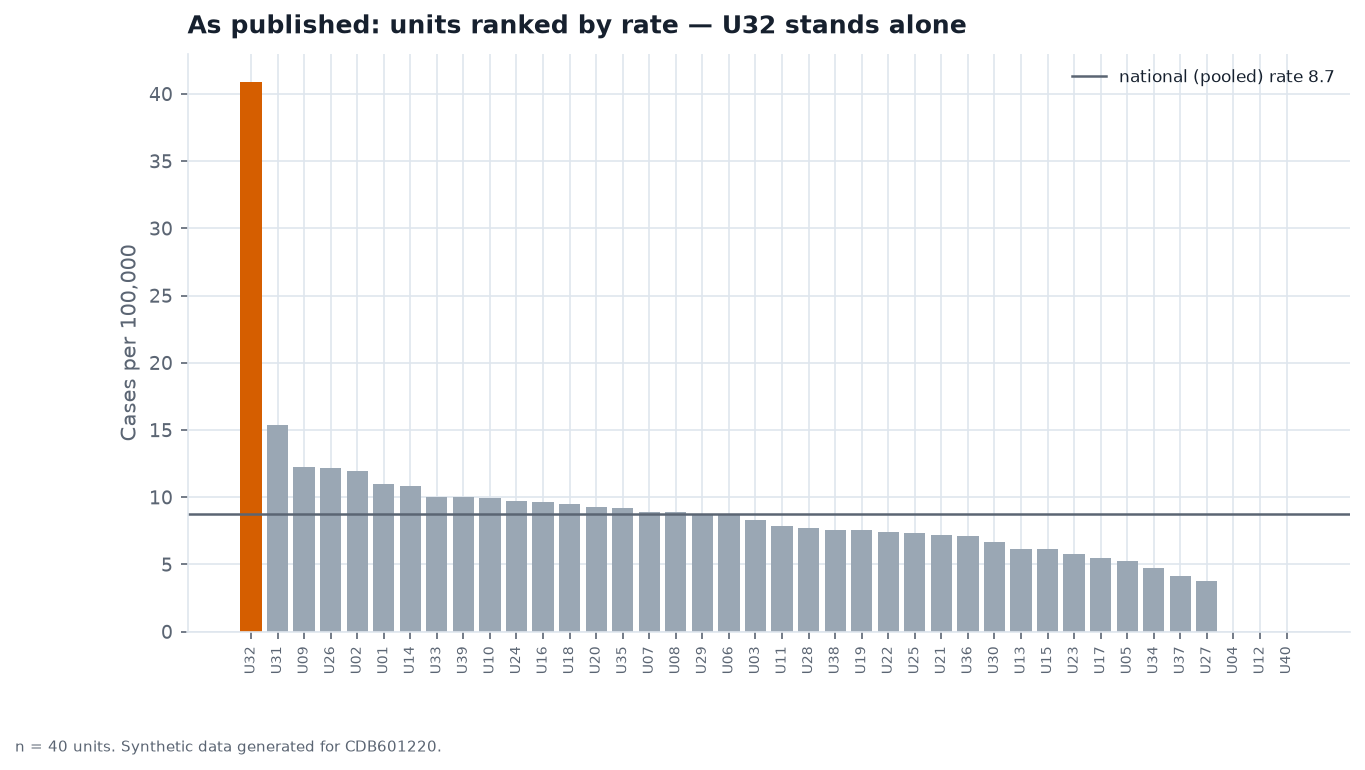

units 40 | pooled 8.72 (brief 8.72) | U32 40.9 = 4.7x national (brief 40.9, 4.7x) from 9 cases in 22,000 people
10 units with populations over 100,000 fall between 5.5 and 12.0   (brief: 10, 5.5–12.0)


In [17]:
sa = pd.read_csv(DATA + "smallarea_cases.csv"); sa["rate"] = sa.cases / sa.population * 1e5
pool6 = sa.cases.sum() / sa.population.sum() * 1e5
d6 = sa.sort_values("rate", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 5.0))
ax.bar(d6.unit, d6.rate, color=[PAL["highlight"] if u == "U32" else PAL["muted"] for u in d6.unit], width=0.8)
ax.axhline(pool6, color=PAL["ink_soft"], lw=1.2, label=f"national (pooled) rate {pool6:.1f}")
ax.set_ylabel("Cases per 100,000"); ax.tick_params(axis="x", labelsize=6.5, rotation=90); ax.legend(fontsize=8)
ax.set_title("As published: units ranked by rate — U32 stands alone", loc="left")
save(fig, "partA_case6_rebuild.png", "n = 40 units. " + SRC)
plt.show()
u = sa[sa.unit == "U32"].iloc[0]
big6 = sa[sa.population > 1e5]
print(f"units {len(sa)} | pooled {pool6:.2f} (brief 8.72) | U32 {u.rate:.1f} = {u.rate/pool6:.1f}x national (brief 40.9, 4.7x) from {int(u.cases)} cases in {int(u.population):,} people")
print(f"{len(big6)} units with populations over 100,000 fall between {big6.rate.min():.1f} and {big6.rate.max():.1f}   (brief: 10, 5.5–12.0)")

### 6b · The conclusion and the decoy

In [18]:
lam6 = pool6 / 1e5 * sa.population
sa["lo"] = np.maximum((lam6 - 1.96*np.sqrt(lam6)) / sa.population * 1e5, 0); sa["hi"] = (lam6 + 1.96*np.sqrt(lam6)) / sa.population * 1e5
sa["p_up"] = stats.poisson.sf(sa.cases - 1, lam6)
u = sa[sa.unit == "U32"].iloc[0]
print(f"U32 expected {lam6[sa.unit=='U32'].iloc[0]:.2f} cases, observed {int(u.cases)}; 95% band at this population: 0 – {u.hi:.1f} = up to {u.hi/pool6:.1f}x the national rate by chance")
print(f"exact Poisson P(X>=9) = {u.p_up:.5f};  x40 units = {min(u.p_up*40,1):.4f}")
print("units outside the 95% funnel:", sa[(sa.rate > sa.hi) | (sa.rate < sa.lo)].unit.tolist(), "of 40")
small = sa[sa.population < 30000]
print(f"\n{len(small)} units under 30,000 people: rates run {small.rate.min():.1f} – {small.rate.max():.1f}  (a 'cold spot' and a 'hotspot' from the same small units)")
print("zero-case units:", sa[sa.cases == 0].unit.tolist())
print(f"\nmedian rate of units > 100,000 people: {big6.rate.median():.1f}  (national {pool6:.1f}); sd of rate: <50k people = {sa[sa.population<50000].rate.std():.1f}, >=50k = {sa[sa.population>=50000].rate.std():.1f}")

U32 expected 1.92 cases, observed 9; 95% band at this population: 0 – 21.1 = up to 2.4x the national rate by chance
exact Poisson P(X>=9) = 0.00018;  x40 units = 0.0070
units outside the 95% funnel: ['U32'] of 40

13 units under 30,000 people: rates run 0.0 – 40.9  (a 'cold spot' and a 'hotspot' from the same small units)
zero-case units: ['U04', 'U12', 'U40']

median rate of units > 100,000 people: 9.2  (national 8.7); sd of rate: <50k people = 8.5, >=50k = 2.2


**Conclusion invited:** "U32 is a hotspot: 4.7× the national rate — send resources."

**The decoy (first objection):** *"The arithmetic is right (9 / 22,000 = 40.9 per 100,000), so the rate is a fact."* The rate is a fact; the *inference* is not. This objection only partly holds up, and I will say so honestly: U32 **is** the one unit outside the 95% funnel (9 cases against 1.92 expected; exact P(X ≥ 9) = 0.00018, ≈ 0.007 after allowing for 40 units), so it is not *pure* noise by the pooled-rate yardstick. But **nothing else is**: the **10 units over 100,000 people sit between 5.5 and 12.0**, and every other apparent extreme — the three zero-case units, U31's 15.4 from 4 cases — lies *inside* the band. (The data dictionary says all 40 units share the same true rate, so U32 would be a chance extreme — something the map alone cannot tell you.)

**The mechanism — the small denominator.** The noise in a rate scales as 1/√(expected cases). At 22,000 people only **1.9 cases** are expected, so chance alone produces rates up to **21.1 per 100,000 — 2.4× the national rate**, and every unit under ~30,000 people swings between 0 and 41. A ranked map treats a 22,000-person unit and a 268,500-person unit as equally trustworthy points on one scale. U32's 4.7× is built on **nine cases**.

### 6c · The redesign — the funnel plot (rate against the population behind it)

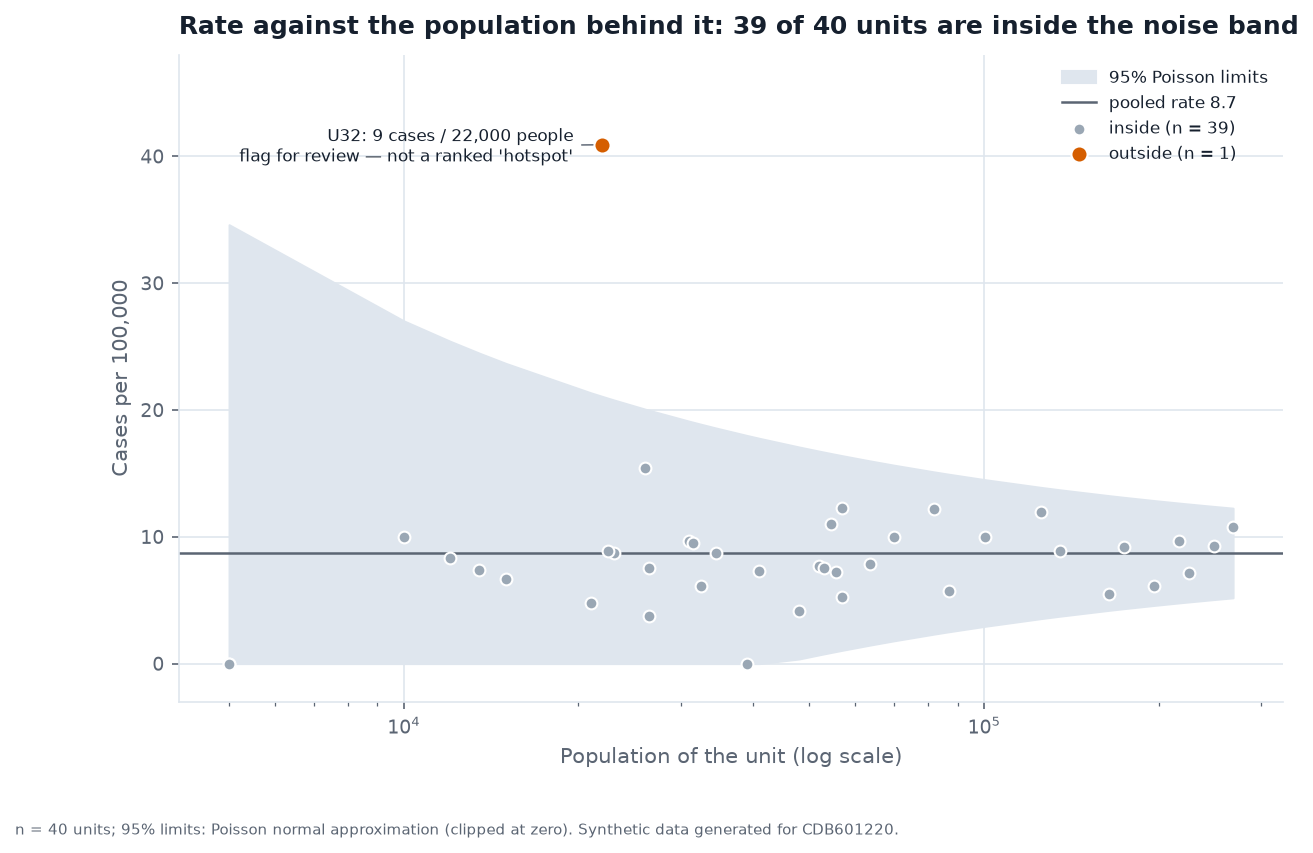

In [19]:
fl6 = g.funnel_limits(sa.population, pool6)
fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.fill_between(fl6.population, fl6.lo, fl6.hi, color=PAL["grid"], zorder=1, label="95% Poisson limits")
ax.axhline(pool6, color=PAL["ink_soft"], lw=1.2, zorder=2, label=f"pooled rate {pool6:.1f}")
out6 = (sa.rate > sa.hi) | (sa.rate < sa.lo)
ax.scatter(sa.population[~out6], sa.rate[~out6], s=32, color=PAL["muted"], edgecolor="white", zorder=3, label=f"inside (n = {(~out6).sum()})")
ax.scatter(sa.population[out6], sa.rate[out6], s=60, color=PAL["highlight"], edgecolor="white", zorder=4, label=f"outside (n = {out6.sum()})")
for _, r_ in sa[out6].iterrows():
    ax.annotate(f"{r_.unit}: {int(r_.cases)} cases / {int(r_.population):,} people\nflag for review — not a ranked 'hotspot'", (r_.population, r_.rate), xytext=(-14, -8), ha="right", textcoords="offset points", fontsize=8,
                arrowprops=dict(arrowstyle="-", lw=.7, color=PAL["ink_soft"]))
ax.set_xscale("log"); ax.set_ylim(-3, 48); ax.set_xlabel("Population of the unit (log scale)"); ax.set_ylabel("Cases per 100,000"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("Rate against the population behind it: 39 of 40 units are inside the noise band", loc="left")
save(fig, "partA_case6_redesign.png", "n = 40 units; 95% limits: Poisson normal approximation (clipped at zero). " + SRC)
plt.show()

---
## Case 7 · "District income and case rate are only weakly related — r is about −0.31"
`district_health.csv` · recipe: correlate `income_pc_usd` against `cases / population * 1e5` across the 24 districts

### 7a · Rebuild

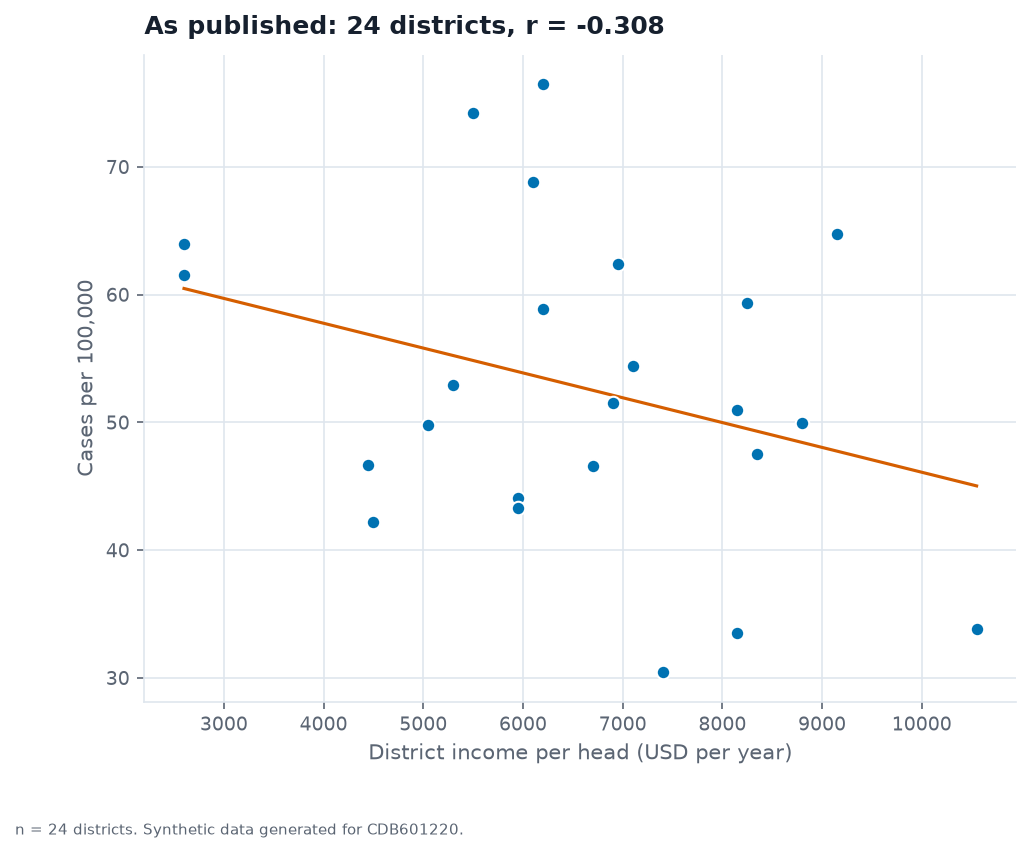

r = -0.308 across 24 districts   (brief: −0.308)


In [20]:
r7 = dh.income_pc_usd.corr(dh.rate)
fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.scatter(dh.income_pc_usd, dh.rate, s=42, color=PAL["series"][0], edgecolor="white", zorder=3)
b, a = np.polyfit(dh.income_pc_usd, dh.rate, 1); xs = np.array([dh.income_pc_usd.min(), dh.income_pc_usd.max()])
ax.plot(xs, a + b * xs, color=PAL["highlight"], lw=1.5)
ax.set_xlabel("District income per head (USD per year)"); ax.set_ylabel("Cases per 100,000")
ax.set_title(f"As published: 24 districts, r = {r7:+.3f}", loc="left")
save(fig, "partA_case7_rebuild.png", "n = 24 districts. " + SRC)
plt.show()
print(f"r = {r7:+.3f} across {len(dh)} districts   (brief: −0.308)")

### 7b · The conclusion and the decoy

In [21]:
zn = dh.groupby("zone").agg(cases=("cases", "sum"), pop=("population", "sum"), inc=("income_pc_usd", "mean"), n=("code", "size"))
zn["rate"] = zn.cases / zn["pop"] * 1e5
print(zn.round(1).to_string())
print(f"\nr(income, rate) across the 6 zones = {zn.inc.corr(zn.rate):+.3f}   (brief: district −0.308 / zone −0.889)")
dh["inc_w"] = dh.income_pc_usd
zw = dh.groupby("zone").apply(lambda t: (t.income_pc_usd * t.population).sum() / t.population.sum(), include_groups=False)
print(f"population-weighted zone income instead of the plain mean: r = {zw.corr(zn.rate):+.3f}")
print("\nwithin each zone (4 districts each):")
print(dh.groupby("zone").apply(lambda t: t.income_pc_usd.corr(t.rate), include_groups=False).round(2).to_string())

# 5,000 random ways of cutting the same 24 districts into six zones of four (NOT contiguous — only the zoning varies)
rng = np.random.default_rng(0)
inc, cas, pop_ = dh.income_pc_usd.to_numpy(float), dh.cases.to_numpy(float), dh.population.to_numpy(float)
rs = []
for _ in range(5000):
    G = rng.permutation(24).reshape(6, 4)
    zi, zr = inc[G].mean(1), cas[G].sum(1) / pop_[G].sum(1) * 1e5
    rs.append(np.corrcoef(zi, zr)[0, 1])
rs = np.array(rs)
print(f"\n5,000 random 6-zone partitions: r from {rs.min():+.2f} to {rs.max():+.2f}; middle 90% {np.percentile(rs,5):+.2f} to {np.percentile(rs,95):+.2f}; share with r < −0.5: {(rs < -0.5).mean():.0%}")

      cases       pop     inc  n  rate
zone                                  
P1     3208   6252000  6687.5  4  51.3
P2     4934  10351000  7400.0  4  47.7
P3     2837   6964000  7100.0  4  40.7
P4     6715   9941000  5312.5  4  67.5
P5     2388   3783000  6237.5  4  63.1
P6    10482  20566000  6475.0  4  51.0

r(income, rate) across the 6 zones = -0.889   (brief: district −0.308 / zone −0.889)
population-weighted zone income instead of the plain mean: r = -0.746

within each zone (4 districts each):
zone
P1   -0.67
P2   -0.06
P3   -0.69
P4    0.26
P5    0.04
P6    0.77

5,000 random 6-zone partitions: r from -0.99 to +0.95; middle 90% -0.84 to +0.41; share with r < −0.5: 37%


**Conclusion invited:** "income hardly matters for case rate (r ≈ −0.31)."

**The decoy (first objection):** *"If zone-level r is so strong, it is only because n = 6 — six points always look tidier."* Part true, and I rule it out only partly: with six points a high |r| is easier to get (random regroupings of the same 24 districts produce r anywhere from −0.99 to +0.95, middle 90% −0.84 to +0.41, and 37% of them give r below −0.5). But the **official zoning** is not random, it produces **r = −0.889**, and the population-weighted version is **−0.746** — still strong. So the number genuinely depends on how the land is cut.

**The mechanism — the boundaries (MAUP).** The same 24 districts and the same data give **r = −0.308 by district and −0.889 by zone** — the answer depends on the scale and the lines. Averaging within zones removes within-zone scatter, and that scatter is *not* a nuisance: inside zones the district-level correlation runs from **−0.69 (P3) to +0.77 (P6)**, so the zone-level relationship is absent or reversed inside four of the six zones (−0.06, +0.26, +0.04, +0.77). Neither number is "the" correlation; each is a statement about one set of areal units, and a claim that quotes r without naming the scale is incomplete.

### 7c · The redesign — both scales on one chart, each labelled with its r

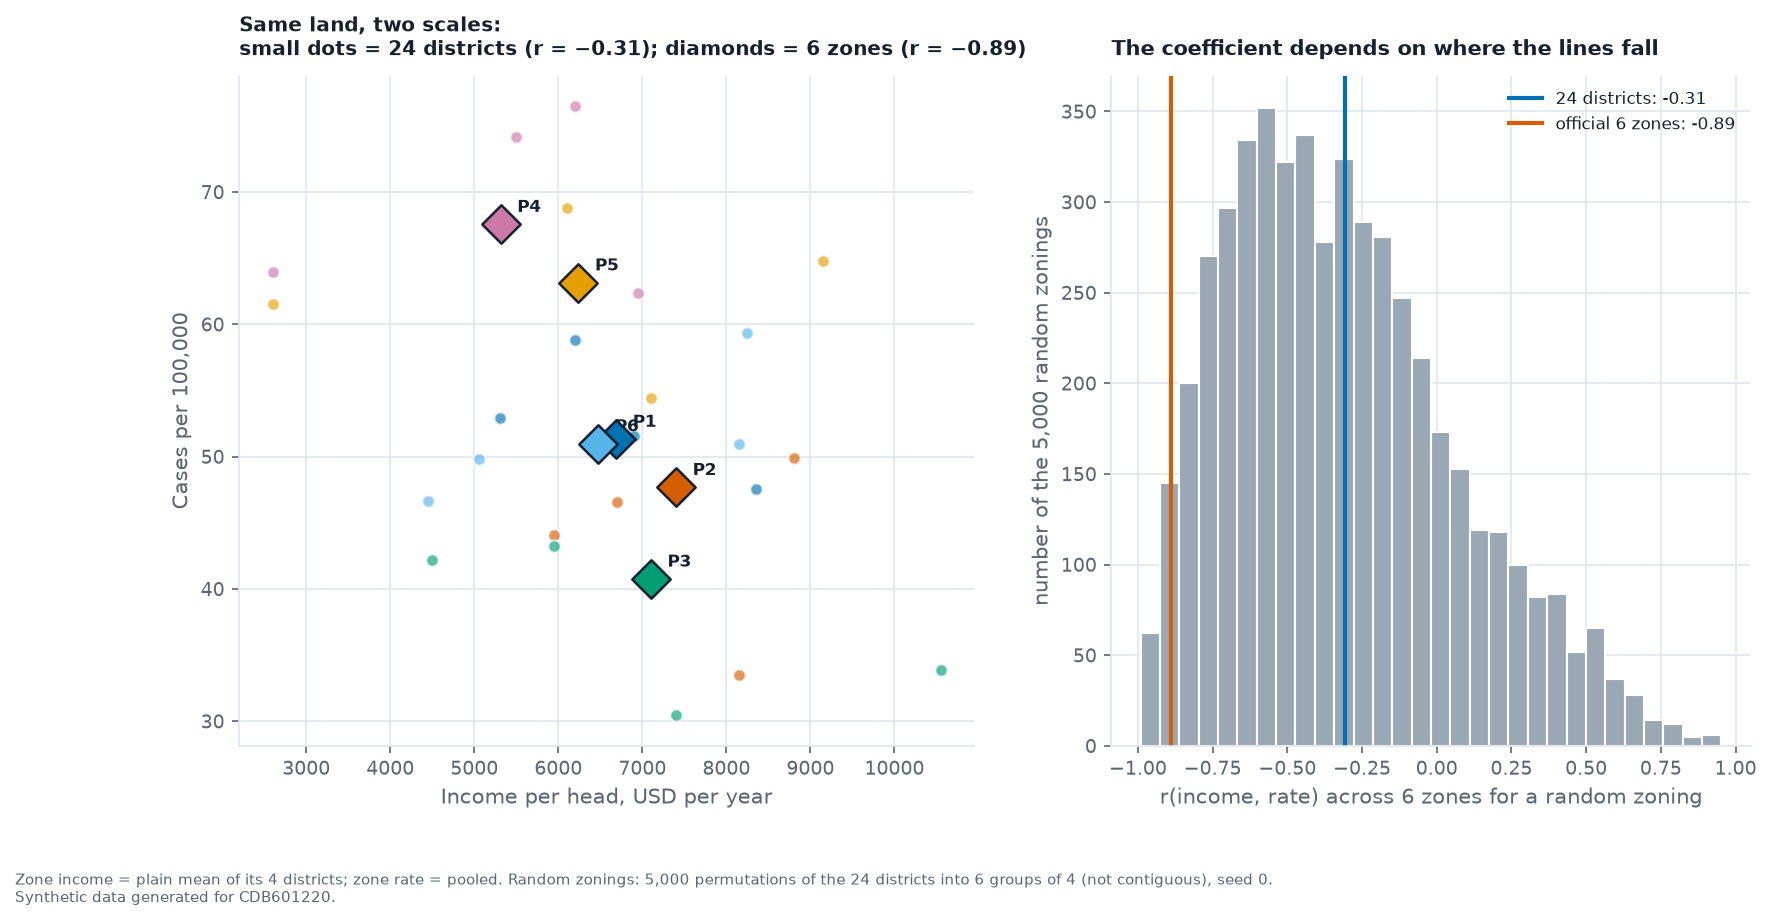

In [22]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw={"width_ratios": [1.15, 1]})
zc = dict(zip(sorted(dh.zone.unique()), ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]))
for z_, t in dh.groupby("zone"):
    a1.scatter(t.income_pc_usd, t.rate, s=34, color=zc[z_], alpha=.65, edgecolor="white", zorder=3)
    a1.scatter(zn.inc[z_], zn.rate[z_], s=170, marker="D", color=zc[z_], edgecolor=PAL["ink"], linewidth=1.2, zorder=5)
    a1.annotate(z_, (zn.inc[z_], zn.rate[z_]), xytext=(8, 6), textcoords="offset points", fontsize=8, fontweight="bold")
a1.set_xlabel("Income per head, USD per year"); a1.set_ylabel("Cases per 100,000")
a1.set_title("Same land, two scales:\nsmall dots = 24 districts (r = −0.31); diamonds = 6 zones (r = −0.89)", loc="left", fontsize=9.5)
a2.hist(rs, bins=30, color=PAL["muted"], edgecolor="white")
a2.axvline(r7, color=PAL["series"][0], lw=2, label=f"24 districts: {r7:+.2f}"); a2.axvline(zn.inc.corr(zn.rate), color=PAL["highlight"], lw=2, label=f"official 6 zones: {zn.inc.corr(zn.rate):+.2f}")
a2.set_xlabel("r(income, rate) across 6 zones for a random zoning"); a2.set_ylabel("number of the 5,000 random zonings"); a2.legend(fontsize=8, loc="upper right")
a2.set_title("The coefficient depends on where the lines fall", loc="left", fontsize=10)
save(fig, "partA_case7_redesign.png", "Zone income = plain mean of its 4 districts; zone rate = pooled. Random zonings: 5,000 permutations of the 24 districts into 6 groups of 4 (not contiguous), seed 0. " + SRC)
plt.show()

---
## Case 8 · "This is a rural outbreak — look how much of the map is dark"
`district_health.csv` + `districts.geojson` · recipe: choropleth the rate with five natural breaks, describe the map by how much of it is in the top two classes

### 8a · Rebuild

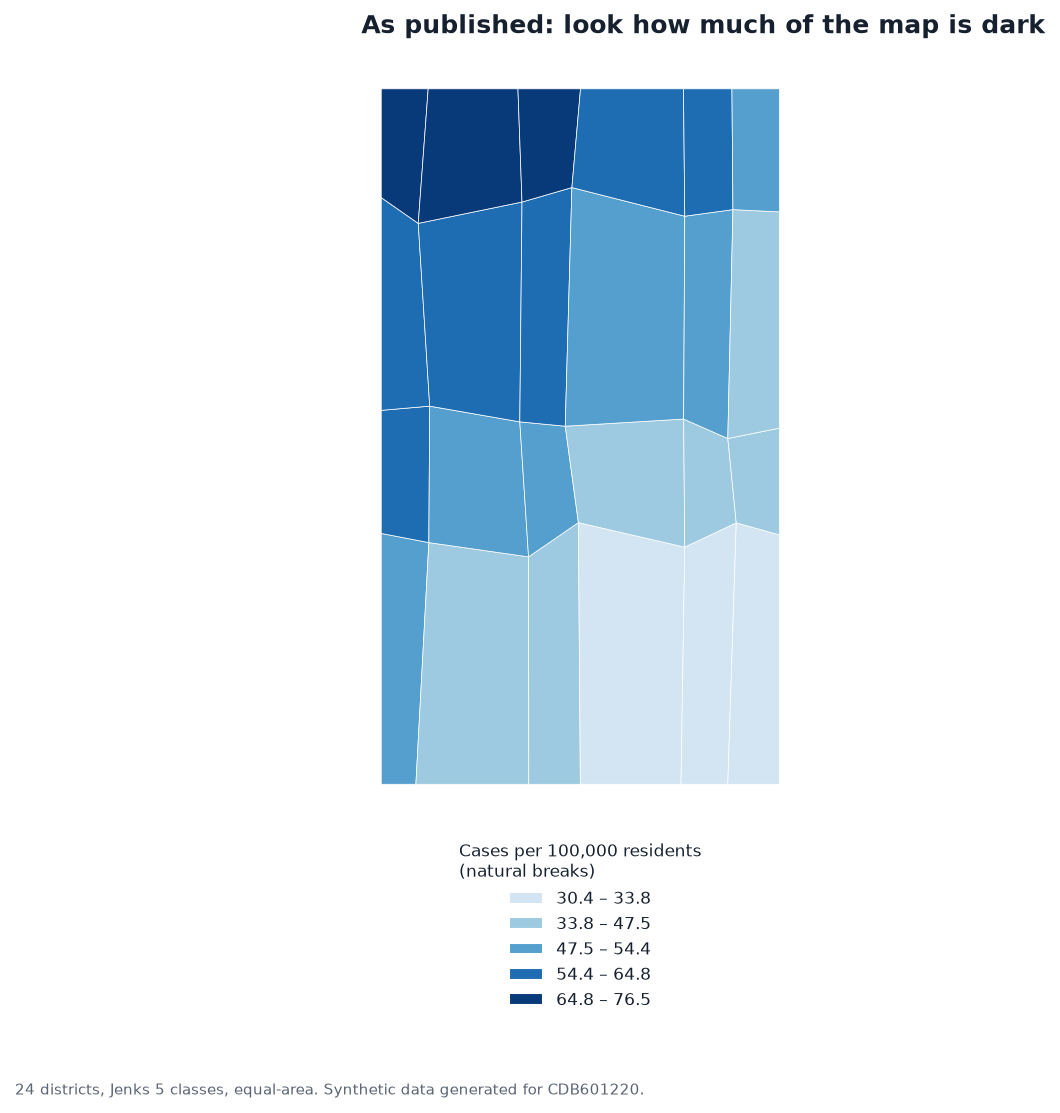

five most populous districts: 12.6% of the land area, 59.9% of the population   (brief: 12.6% / 59.9%)


In [23]:
fig, ax = plt.subplots(figsize=(7.5, 7.5)); fig.subplots_adjust(bottom=0.2)
e8 = g.choropleth(ax, feats, dict(zip(dh.code, dh.rate)), "natural", 5, legend_title="Cases per 100,000 residents\n(natural breaks)", fmt="{:.1f}", legend_loc="upper center", legend_anchor=(0.5, -0.01))
ax.set_title("As published: look how much of the map is dark", loc="left")
save(fig, "partA_case8_rebuild.png", "24 districts, Jenks 5 classes, equal-area. " + SRC)
plt.show()
dh["dens"] = dh.population / dh.area_km2
t5 = dh.nlargest(5, "population")
print(f"five most populous districts: {t5.area_km2.sum()/dh.area_km2.sum():.1%} of the land area, {t5.population.sum()/dh.population.sum():.1%} of the population   (brief: 12.6% / 59.9%)")
dh["cls"] = g.class_of(dh.rate, e8)

### 8b · The conclusion and the decoy

In [24]:
tab = dh.groupby("cls").agg(districts=("code", "size"), land=("area_km2", "sum"), people=("population", "sum"))
tab["share_of_land"], tab["share_of_people"] = tab.land / tab.land.sum(), tab.people / tab.people.sum()
print(tab[["districts", "share_of_land", "share_of_people"]].round(3).to_string())
top2 = dh.cls >= 3
print(f"\ntop two classes: {top2.sum()} districts, {dh.area_km2[top2].sum()/dh.area_km2.sum():.1%} of the land but {dh.population[top2].sum()/dh.population.sum():.1%} of the people")
print(f"r(rate, density) = {dh.rate.corr(dh.dens):+.3f}   r(rate, log density) = {dh.rate.corr(np.log(dh.dens)):+.3f}")
lo_ = dh[dh.dens < dh.dens.median()]; hi_ = dh[dh.dens >= dh.dens.median()]
print(f"pooled rate — sparser half: {lo_.cases.sum()/lo_.population.sum()*1e5:.1f}   denser half: {hi_.cases.sum()/hi_.population.sum()*1e5:.1f}  (national {pooled:.1f})")
print(f"density range {dh.dens.min():.0f} – {dh.dens.max():.0f} people/km²")

     districts  share_of_land  share_of_people
cls                                           
0            3          0.181            0.034
1            6          0.254            0.206
2            6          0.253            0.495
3            6          0.229            0.192
4            3          0.083            0.073

top two classes: 9 districts, 31.2% of the land but 26.5% of the people
r(rate, density) = +0.001   r(rate, log density) = +0.137
pooled rate — sparser half: 52.0   denser half: 53.0  (national 52.8)
density range 6 – 327 people/km²


**Conclusion invited:** "a rural outbreak — a lot of the map is dark, and the big empty-looking districts are the dark ones."

**The decoy (first objection):** *"Maybe rate really is higher where people are sparse."* Ruled out with the data: **r(rate, density) = +0.001** (+0.137 on log density), and the pooled rate in the sparser half of the districts is **52.0** against **53.0** in the denser half. Rate has nothing to do with density here — so "rural outbreak" is unsupported *and* "urban outbreak" would be too.

**The mechanism — area read as people.** A choropleth's ink is proportional to **land area**, but the question is about **people**. The five most populous districts hold **59.9% of the population on 12.6% of the land**, so they get about an eighth of the ink while carrying most of the risk-exposed people. The top two classes cover **31.2% of the land but only 26.5% of the people**: "how much of the map is dark" is a statement about land. No careful colouring fixes that — the channel itself (area) is the wrong one for a per-person quantity.

### 8c · The redesign — land share vs people share, side by side

ValueError: 'le|ft' is not a valid value for loc. Supported values are 'left', 'center', 'right'

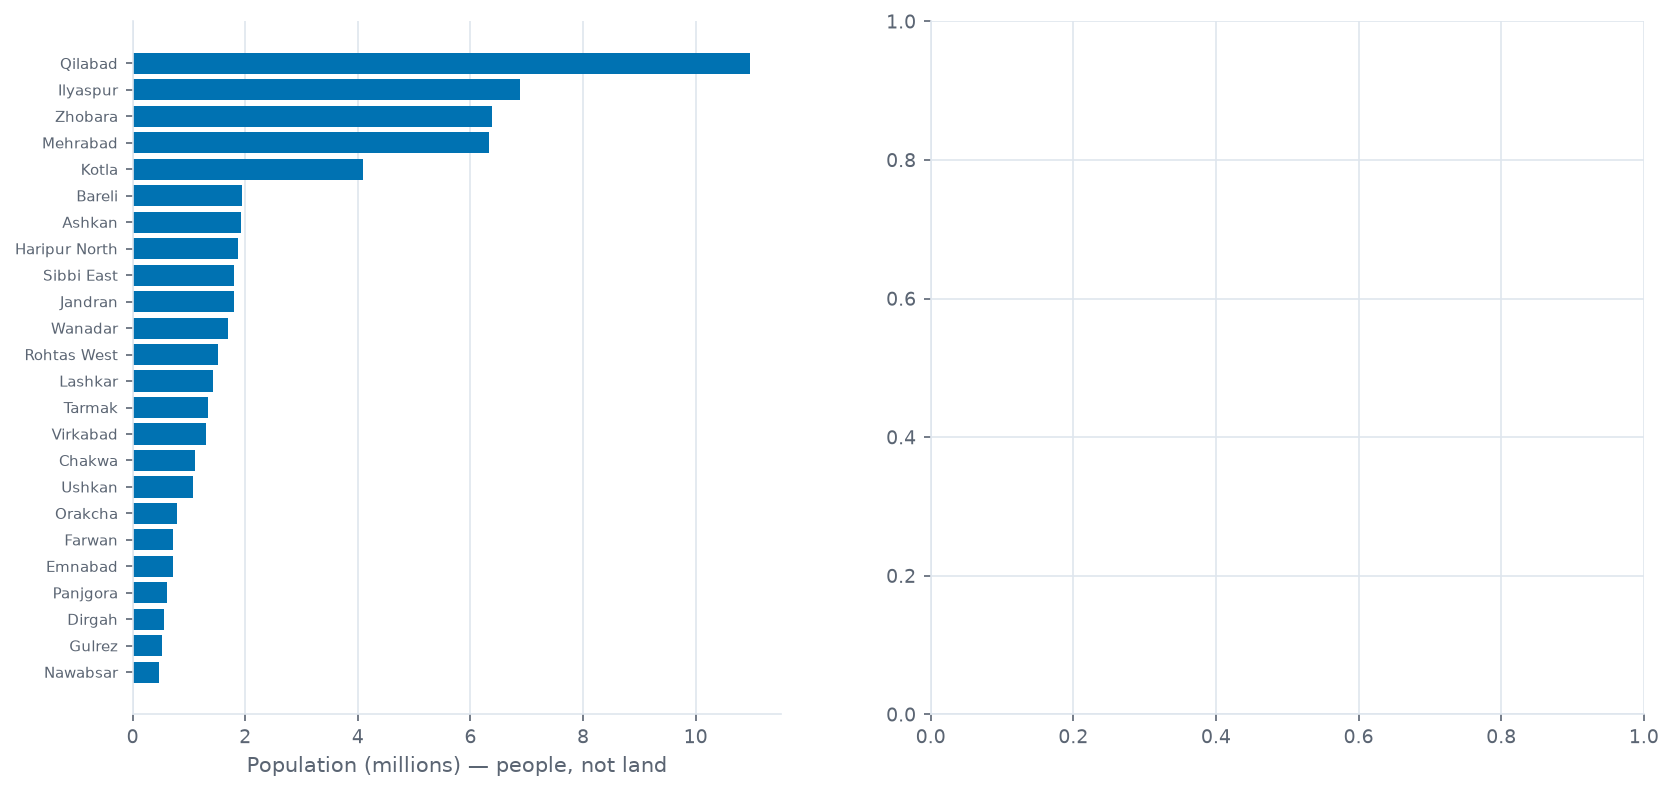

In [25]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6.0), gridspec_kw={"width_ratios": [1, 1.1]}); fig.subplots_adjust(wspace=0.22)
d8 = dh.sort_values("population", ascending=True)
a1.barh(d8.district, d8.population / 1e6, color=PAL["series"][0]); a1.set_xlabel("Population (millions) — people, not land"); a1.tick_params(axis="y", labelsize=7); a1.grid(axis="y", visible=False)
a1.set_title("Where the 57.9 M people live", loc="le|ft", fontsize=11)
w = 0.38; xx = np.arange(5)
a2.bar(xx - w/2, tab.share_of_land * 100, w, color=PAL["muted"], label="share of LAND (what the map's ink shows)")
a2.bar(xx + w/2, tab.share_of_people * 100, w, color=PAL["highlight"], label="share of PEOPLE")
a2.set_xticks(xx); a2.set_xticklabels([f"{e8[k]:.0f}–{e8[k+1]:.0f}" for k in range(5)]); a2.set_xlabel("Rate class (cases per 100,000, natural breaks; darker map = higher)"); a2.set_ylabel("% of federation")
a2.legend(fontsize=8, loc="upper right"); a2.set_title("The dark classes: 31% of land, 26% of people", loc="left", fontsize=11)
save(fig, "partA_case8_redesign.png", "24 districts. Same Jenks classes as the published map. " + SRC)
plt.show()

---
## Case 9 · "Region A is the stronger of the two — its profile encloses visibly more area"
`region_profiles.csv` · recipe: radar chart, six axes in file order, both profiles filled with transparency, compare the enclosed areas

### 9a · Rebuild

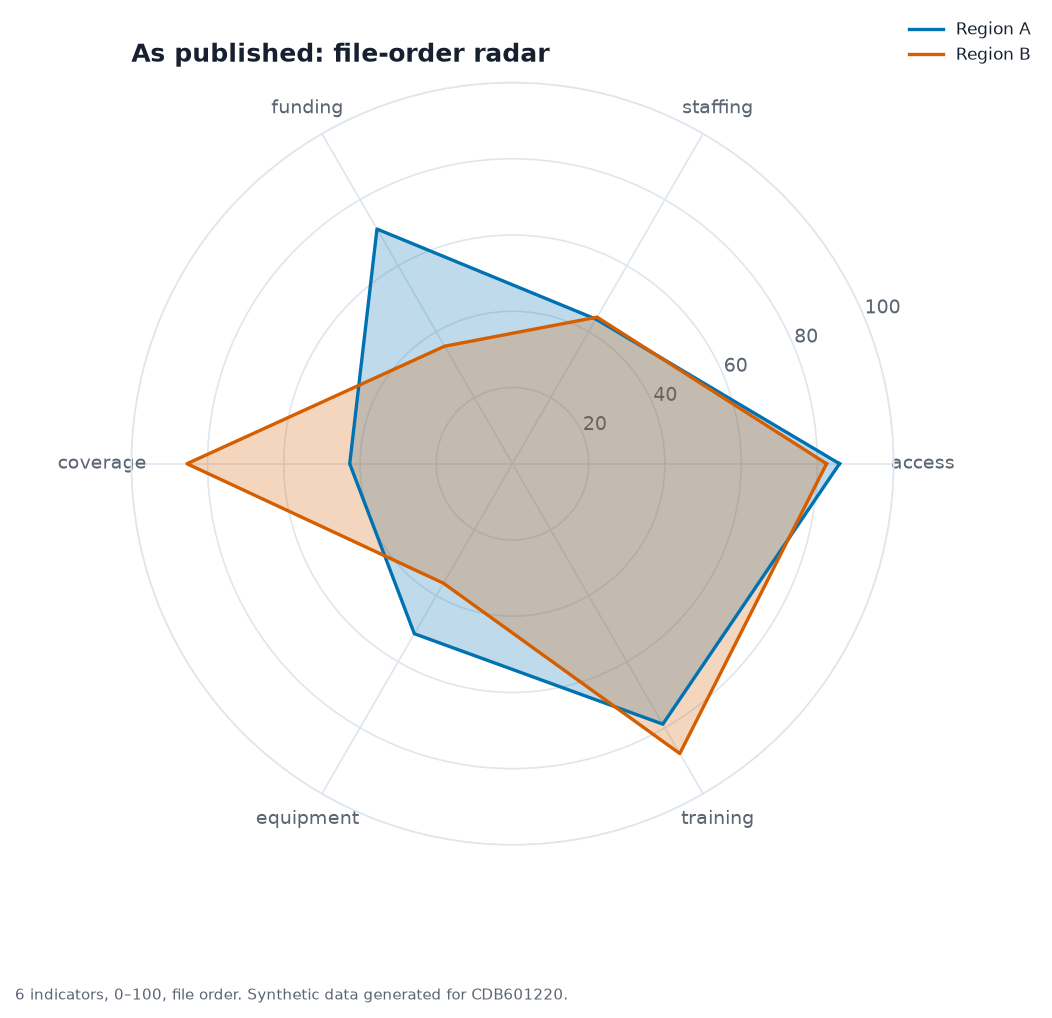

means: A 62.3, B 62.0  (difference 0.33 on a 0–100 scale)   (brief: 62.3 / 62.0 / 0.33)
enclosed areas in file order: A 9,933, B 9,433   (brief: 9,933 / 9,433)


In [27]:
rp = pd.read_csv(DATA + "region_profiles.csv")
def radar_area(v):
    v = np.asarray(v, float); th = 2 * np.pi / len(v)
    return 0.5 * np.sin(th) * np.sum(v * np.roll(v, -1))
ang = np.linspace(0, 2 * np.pi, len(rp), endpoint=False); angc = np.append(ang, ang[0])
fig = plt.figure(figsize=(6.6, 6.6)); ax = fig.add_subplot(111, projection="polar")
for col, c_ in [("region_a", PAL["series"][0]), ("region_b", PAL["highlight"])]:
    v = np.append(rp[col], rp[col].iloc[0]); ax.plot(angc, v, color=c_, lw=1.6, label=col.replace("_", " ").title()); ax.fill(angc, v, color=c_, alpha=.25)
ax.set_xticks(ang); ax.set_xticklabels(rp.indicator); ax.set_ylim(0, 100); ax.legend(loc="upper right", bbox_to_anchor=(1.2, 1.1), fontsize=8)
ax.set_title("As published: file-order radar", loc="left")
save(fig, "partA_case9_rebuild.png", "6 indicators, 0–100, file order. " + SRC)
plt.show()
aA, aB = radar_area(rp.region_a), radar_area(rp.region_b)
print(f"means: A {rp.region_a.mean():.1f}, B {rp.region_b.mean():.1f}  (difference {rp.region_a.mean()-rp.region_b.mean():.2f} on a 0–100 scale)   (brief: 62.3 / 62.0 / 0.33)")
print(f"enclosed areas in file order: A {aA:,.0f}, B {aB:,.0f}   (brief: 9,933 / 9,433)")

### 9b · The conclusion and the decoy

In [28]:
print(rp.assign(diff=rp.region_a - rp.region_b).to_string(index=False))
print(f"\nindicators where A is higher: {(rp.region_a > rp.region_b).sum()} of 6; where B is higher: {(rp.region_b > rp.region_a).sum()} of 6")
import itertools
AA, BB = [], []
for p in itertools.permutations(range(6)):
    AA.append(radar_area(rp.region_a.to_numpy()[list(p)])); BB.append(radar_area(rp.region_b.to_numpy()[list(p)]))
AA, BB = np.array(AA), np.array(BB)
print(f"\nover all {len(AA)} axis orders: A's enclosed area ranges {AA.min():,.0f} – {AA.max():,.0f}; B's ranges {BB.min():,.0f} – {BB.max():,.0f}")
print(f"A encloses MORE area in {(AA > BB).mean():.0%} of orders and LESS in {(AA < BB).mean():.0%}")
print(f"the winner's margin in the file order ({aA-aB:,.0f}) is inside the range one region's own area swings just by re-ordering ({AA.max()-AA.min():,.0f})")

indicator  region_a  region_b  diff
   access      85.8      82.4   3.4
 staffing      43.8      44.4  -0.6
  funding      71.1      35.6  35.5
 coverage      42.7      85.4 -42.7
equipment      51.5      36.2  15.3
 training      78.9      87.8  -8.9

indicators where A is higher: 3 of 6; where B is higher: 3 of 6

over all 720 axis orders: A's enclosed area ranges 9,366 – 10,443; B's ranges 8,564 – 10,555
A encloses MORE area in 65% of orders and LESS in 35%
the winner's margin in the file order (501) is inside the range one region's own area swings just by re-ordering (1,077)


**Conclusion invited:** "Region A is stronger — look at all that extra area."

**The decoy (first objection):** *"A has the higher average rating, so it is genuinely stronger."* Ruled out: the means are **62.3 vs 62.0 — a 0.33-point gap on a 0–100 scale** — and the profiles are completely different shapes (A beats B on 3 indicators, B beats A on 3; funding 71 vs 36, coverage 43 vs 85). There is no honest "stronger" on these numbers.

**The mechanism — angle and axis order.** Radar-chart area is ½·sin(60°)·Σ rᵢ·rᵢ₊₁: it is a sum of products of **neighbouring** axes, so it changes when the axes are re-ordered, with the data untouched. Across all 720 orders A's enclosed area ranges **9,366 – 10,443** and B's **8,564 – 10,555**; A wins in only **65%** of orders and loses in 35%. The published margin (9,933 vs 9,433) is smaller than the swing A's own area makes just by re-ordering the spokes. Area on a radar chart is an artefact of the order the CSV happened to be in.

### 9c · The redesign — one position scale, sorted by the gap

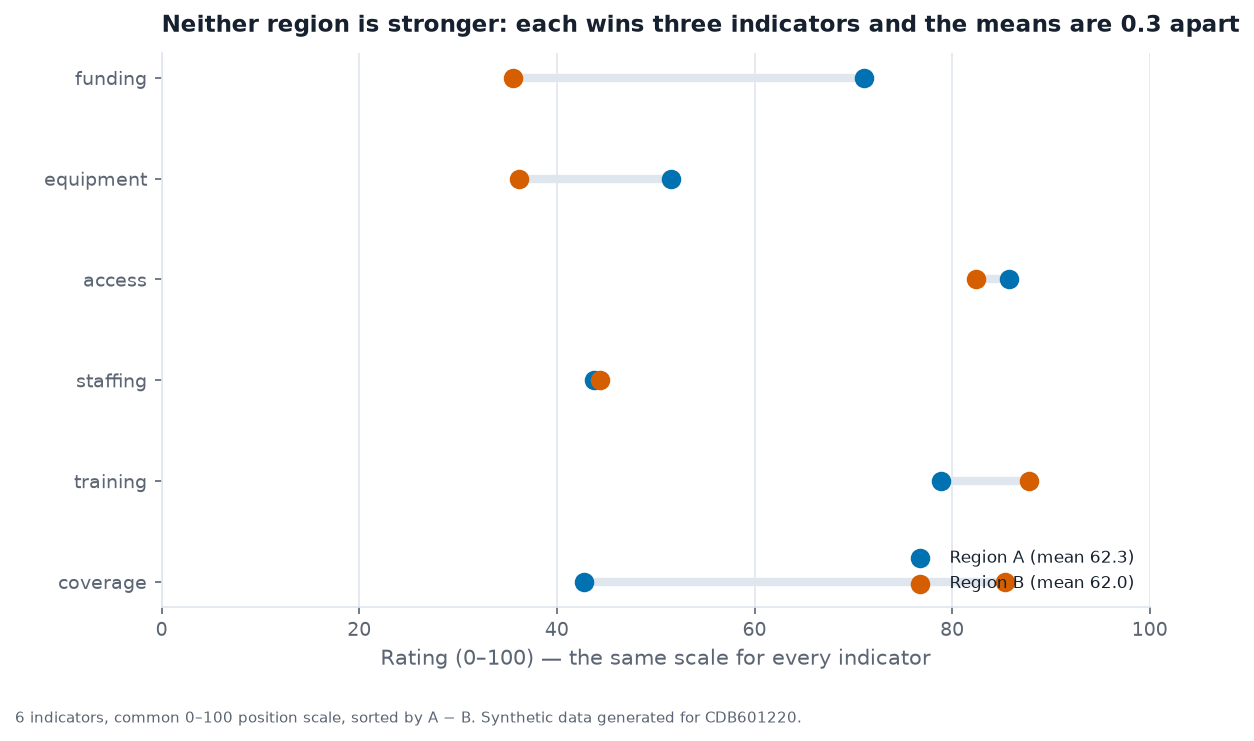

In [29]:
d9 = rp.assign(diff=rp.region_a - rp.region_b).sort_values("diff")
fig, ax = plt.subplots(figsize=(8.5, 4.8)); y = np.arange(len(d9))
ax.hlines(y, d9.region_b, d9.region_a, color=PAL["grid"], lw=4, zorder=1)
ax.scatter(d9.region_a, y, s=70, color=PAL["series"][0], zorder=3, label=f"Region A (mean {rp.region_a.mean():.1f})")
ax.scatter(d9.region_b, y, s=70, color=PAL["highlight"], zorder=3, label=f"Region B (mean {rp.region_b.mean():.1f})")
ax.set_yticks(y); ax.set_yticklabels(d9.indicator); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_xlabel("Rating (0–100) — the same scale for every indicator"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Neither region is stronger: each wins three indicators and the means are 0.3 apart", loc="left", fontsize=11)
save(fig, "partA_case9_redesign.png", "6 indicators, common 0–100 position scale, sorted by A − B. " + SRC)
plt.show()

---
## Summary table

| # | Claim | Lying channel / boundary | Number that proves it |
|---|---|---|---|
| 1 | Pop. and access unrelated | **area** driven by pop² | area ratio 346,921× (pop ratio 589×) |
| 2 | Outbreak in 3 districts | raw count = **population** | r(cases, pop) = +0.986; top-3 overlap 0 |
| 3 | GDP barely varies | min–max **scaling** pinned by 1 outlier | 58 of 60 below 0.10 |
| 4 | No access–case link | PCP **axis order** | strongest pair 3 axes apart; r = −0.799 |
| 5 | Five-level gradient | **quantile classes** over a flat range | spread 7.2% of mean; χ² = 2.3 on 23 df |
| 6 | U32 hotspot | **small denominator** | 1.9 expected cases; band up to 2.4× |
| 7 | Income weakly related | **boundaries / scale** (MAUP) | r −0.31 (district) vs −0.89 (zone) |
| 8 | Rural outbreak | **area read as people** | 12.6% land / 59.9% people |
| 9 | A is stronger | radar **area depends on axis order** | A wins 65% of 720 orders; means 0.33 apart |